# PW2 · Data processing

## 1 · Configuration
- DATA_DIR : reads directly from Google Drive (`MyDrive/Neuroengeneering_PW2/Data2026pw`). Run the mount cell first and allow access.
- the output folder, window length, sampling rate and maximum tracking gap can be set in the following slot
- i set PLOT_RECORDING to my personal recording ID but you can choose whichever you prefer

In [1]:
# Google Colab: mount Google Drive so the data folder is reachable
from google.colab import drive
drive.mount("/content/drive")


Mounted at /content/drive


In [2]:
from pathlib import Path
from tempfile import mkdtemp

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

# Data is read from Google Drive (shared folder Neuroengeneering_PW2 / Data2026pw).
# The shared folder must be added to "My Drive" as a shortcut (it already is for Amirhossein).
DATA_DIR = Path("/content/drive/MyDrive/Neuroengeneering_PW2/Data2026pw")
# Outputs go to your own Drive so they survive after the Colab session ends.
OUTPUT_ROOT = Path("/content/drive/MyDrive/pw2_processed")
SINGLE_PARTICIPANT = False
#PLOT_RECORDING = None
PLOT_RECORDING = "Martina/1"

WINDOW_S = 2.0
STEP_S = 0.2
SAMPLE_HZ = 10
MAX_GAP_S = 0.25
RANDOM_SEED = 42

SAMPLES_PER_WINDOW = round(WINDOW_S * SAMPLE_HZ)
if (min(WINDOW_S, STEP_S, SAMPLE_HZ, MAX_GAP_S) <= 0
        or SAMPLES_PER_WINDOW < 1
        or not np.isclose(SAMPLES_PER_WINDOW, WINDOW_S * SAMPLE_HZ)):
    raise ValueError("Use positive parameters and a window duration containing a whole number of samples.")

N_JOINTS = 32
PELVIS = 0
WRISTS = (7, 14)
EVENT_ORDER = ["start", "pointing", "end"]

## 1b · File inventory
Lists every participant / recording folder that is missing keypoints, tempos or a label file (or has duplicates). Run it after the configuration cell.


In [3]:
# File inventory: which participant / recording folders have incomplete files
import re
from pathlib import Path
import pandas as pd
from IPython.display import display

_LABEL = re.compile(r"visual[\s_\-]*anal", re.IGNORECASE)
rows = []
for participant in sorted(p for p in DATA_DIR.iterdir() if p.is_dir()):
    recordings = sorted(r for r in participant.iterdir() if r.is_dir())
    if not recordings:
        rows.append({"participant": participant.name, "recording": "-", "missing": "no recording folders"})
    for rec in recordings:
        names = [f.name for f in rec.iterdir() if f.is_file()]
        keypoints = [n for n in names if n.startswith("keypoints") and n.endswith(".txt")]
        tempos = [n for n in names if n.startswith("tempos") and n.endswith(".txt")]
        labels = [n for n in names if n.lower().endswith(".txt") and _LABEL.search(n)]
        problems = []
        if not keypoints: problems.append("keypoints")
        if not tempos: problems.append("tempos")
        if not labels: problems.append("visual_analysis (label)")
        if len(keypoints) > 1: problems.append(f"{len(keypoints)} keypoints files")
        if len(labels) > 1: problems.append(f"{len(labels)} label files")
        if keypoints and tempos and len(keypoints) == 1:
            if keypoints[0].replace("keypoints", "tempos", 1) not in tempos:
                problems.append("tempos timestamp does not match keypoints")
        rows.append({"participant": participant.name, "recording": rec.name,
                     "missing": ", ".join(problems), "files": ", ".join(sorted(names))})
inventory = pd.DataFrame(rows)
incomplete = inventory[inventory["missing"] != ""]
print(f"Participants: {inventory.participant.nunique()} | recording folders: {len(inventory)} | incomplete: {len(incomplete)}")
display(incomplete[["participant", "recording", "missing"]].reset_index(drop=True))


Participants: 22 | recording folders: 66 | incomplete: 0


,participant,recording,missing


## 2 · Loading and Validation functions

- Read annotations in file order and remove exact duplicates.
- Read the label file **three lines at a time, in file order**: a group is one gesture if it has one START, one POINTING and one END with START < POINTING < END in time (the order the lines are written in does not matter, and consecutive gestures may overlap slightly). **Only broken gestures are dropped, not the whole recording**: incomplete or out-of-order events, timestamps missing from tempos, gestures outside the 3D track.
- With several body IDs, keep the one tracked for the most frames; 3D rows whose timestamp is not in tempos are removed.
- Gestures with a skeleton in less than MIN_GESTURE_COVERAGE (50%) of their video frames are dropped (poor tracking, e.g. Sule/2).
- Windows that overlap a dropped gesture (± EXCLUDE_PAD_S for partial gestures) are removed, so it is never used as background.
- Check the 3D format and timestamp alignment.
- Centre all joints on the pelvis and express time relative to the recording start.
- Identify windows that avoid tracking gaps longer than MAX_GAP_S.

These functions are defined here and called in the next section. Each 3D row must contain a body ID, a timestamp and 96 coordinates (32 joints × 3). Verify that the tracked body is the annotated participant.

In [4]:
import re

# Label files are named differently by different people, e.g. "visual_analysis.txt",
# "visual_analysis_video1793697053.2165413.txt", "Visual Analysis.txt", "visual_analisys.txt".
# Match any .txt whose name contains "visual" followed by "anal..." (case-insensitive).
LABEL_PATTERN = re.compile(r"visual[\s_\-]*anal", re.IGNORECASE)


def is_label_file(path):
    return path.is_file() and path.suffix.lower() == ".txt" and bool(LABEL_PATTERN.search(path.stem))


def find_label_file(folder, keypoints):
    candidates = sorted(p for p in folder.iterdir() if is_label_file(p))
    if not candidates:
        raise ValueError("Missing label file (no visual_analysis*.txt in folder).")
    if len(candidates) == 1:
        return candidates[0]
    # Several candidates: prefer the one with the same recording timestamp as the keypoints file,
    # then the plain "visual_analysis.txt"; otherwise ask for a manual check.
    stamp = keypoints.stem[len("keypoints"):]
    same_stamp = [p for p in candidates if stamp and stamp in p.stem]
    if len(same_stamp) == 1:
        return same_stamp[0]
    plain = [p for p in candidates if p.name.lower() == "visual_analysis.txt"]
    if len(plain) == 1:
        return plain[0]
    raise ValueError("Several label files, choose one: " + ", ".join(p.name for p in candidates))


# Extra time (s) excluded around a dropped gesture when only part of it is annotated
# (e.g. a POINTING without START). Windows touching an excluded interval are removed,
# so a real but badly annotated gesture is never used as a "no pointing" example.
EXCLUDE_PAD_S = 1.0
# A group of three lines longer than this is not accepted as one gesture.
MAX_GESTURE_S = 10.0
# A gesture is kept only if at least this share of its video frames have a skeleton.
MIN_GESTURE_COVERAGE = 0.5


def read_gestures(path, video_times):
    """Return (good gestures [n,3], dropped list, duplicates, invalid lines).

    Gestures are read in FILE ORDER, three lines at a time. A group is one gesture when it holds
    exactly one START, one POINTING and one END and, in time, START < POINTING < END
    (the order the three lines are written in does not matter, e.g. Ada writes POINTING first).
    Consecutive gestures may overlap slightly in time. If a group is not valid, only its first
    line is dropped and reading continues from the next line, so a missing line costs one gesture.
    """
    events, invalid_lines = [], []
    for line_number, line in enumerate(path.read_text(encoding="utf-8-sig").splitlines(), 1):
        fields = line.split()
        if not fields:
            continue
        try:
            timestamp = float(fields[0]) if len(fields) == 2 else np.nan
        except ValueError:
            timestamp = np.nan
        if len(fields) != 2 or fields[1].lower() not in EVENT_ORDER or not np.isfinite(timestamp):
            invalid_lines.append(f"line {line_number}: '{line.strip()}'")
            continue
        events.append((timestamp, fields[1].lower(), line_number))

    # Remove exact duplicates (same time and label), keeping the first occurrence.
    seen, unique_events = set(), []
    for event in events:
        if event[:2] not in seen:
            seen.add(event[:2])
            unique_events.append(event)
    duplicates = len(events) - len(unique_events)

    good, dropped = [], []

    def drop(fragment, reason):
        times = [t for t, _, _ in fragment]
        labels = "/".join(label.upper() for _, label, _ in fragment)
        lines = ",".join(str(n) for _, _, n in fragment)
        dropped.append({"reason": f"{reason} [{labels}, line {lines}]", "times": times,
                        "exclude": (min(times) - EXCLUDE_PAD_S, max(times) + EXCLUDE_PAD_S)})

    i = 0
    while i < len(unique_events):
        group = unique_events[i:i + 3]
        by_label = {label: t for t, label, _ in group}
        valid = (len(group) == 3 and len(by_label) == 3
                 and by_label["start"] < by_label["pointing"] < by_label["end"]
                 and by_label["end"] - by_label["start"] <= MAX_GESTURE_S)
        if valid:
            good.append([by_label[name] for name in EVENT_ORDER])
            i += 3
        else:
            if len(group) < 3:
                reason = "file ends inside a gesture"
            elif len(by_label) < 3:
                reason = "the 3 lines are not one START, one POINTING and one END"
            elif not by_label["start"] < by_label["pointing"] < by_label["end"]:
                reason = "times not in START < POINTING < END order"
            else:
                reason = f"longer than {MAX_GESTURE_S:g} s"
            # A complete but invalid gesture (e.g. POINTING and END at the same time) is dropped as
            # one gesture when the next line starts a new one; otherwise drop one line and re-align.
            next_is_start = i + 3 >= len(unique_events) or unique_events[i + 3][1] == "start"
            if len(by_label) == 3 and next_is_start:
                drop(group, reason)
                i += 3
            else:
                drop(group[:1], reason)
                i += 1

    kept = []
    for times in good:
        if not np.isin(times, video_times).all():
            dropped.append({"reason": "timestamp not in tempos", "times": times,
                            "exclude": (times[0], times[2])})
        else:
            kept.append(times)
    gestures = np.array(sorted(kept), dtype=float).reshape(-1, 3)
    return gestures, dropped, duplicates, invalid_lines


def load_recording(folder):
    files = sorted(folder.glob("keypoints*.txt"))
    if len(files) != 1:
        raise ValueError(f"Expected one keypoints*.txt file. Files found: {len(files)}.")
    keypoints = files[0]
    tempo_file = folder / keypoints.name.replace("keypoints", "tempos", 1)
    if not tempo_file.is_file():
        raise ValueError("Missing files: " + tempo_file.name)
    label_file = find_label_file(folder, keypoints)

    clock = np.loadtxt(tempo_file, ndmin=2, encoding="utf-8-sig")
    if clock.shape[1] != 1 or len(clock) < 2:
        raise ValueError("The tempos file must contain one timestamp per row.")
    video_times = clock[:, 0]
    if not np.isfinite(video_times).all() or np.any(np.diff(video_times) <= 0):
        raise ValueError("Video timestamps must be finite and strictly increasing.")

    with keypoints.open(encoding="utf-8-sig") as stream:
        rows = (line for line in stream if line.strip() and line.strip().lower() != "none")
        raw = np.loadtxt(rows, ndmin=2)
    if raw.shape[1] != 2 + N_JOINTS * 3 or len(raw) < 2:
        raise ValueError("Unexpected 3D format. Each row must contain an ID, a timestamp and 96 coordinates.")

    # Several body IDs: keep the body tracked for the most frames (the participant);
    # gestures that this body does not cover are dropped further below.
    raw = raw[np.isfinite(raw[:, 0])]
    body_ids, id_counts = np.unique(raw[:, 0], return_counts=True)
    if not len(body_ids):
        raise ValueError("No valid body ID in the keypoints file.")
    body_id = body_ids[id_counts.argmax()]
    other_ids = {f"{b:g}": int(c) for b, c in zip(body_ids, id_counts) if b != body_id}
    raw = raw[raw[:, 0] == body_id]

    # Keep only 3D rows whose timestamp exists in tempos, in increasing order, without repeats.
    rows_not_in_video = int((~np.isin(raw[:, 1], video_times)).sum())
    raw = raw[np.isin(raw[:, 1], video_times)]
    raw = raw[np.argsort(raw[:, 1], kind="stable")]
    raw = raw[np.r_[True, np.diff(raw[:, 1]) > 0]]
    if len(raw) < 2:
        raise ValueError("Fewer than two 3D frames remain after keeping the main body ID.")
    raw_times = raw[:, 1]

    gestures, dropped, duplicates, invalid_lines = read_gestures(label_file, video_times)

    # Drop gestures that start before the first or end after the last 3D frame.
    inside = (gestures[:, 0] >= raw_times[0]) & (gestures[:, 2] <= raw_times[-1])
    for start, pointing, end in gestures[~inside]:
        side = (f"START {start:.4f} is {raw_times[0] - start:.3f} s before the first 3D frame"
                if start < raw_times[0] else
                f"END {end:.4f} is {end - raw_times[-1]:.3f} s after the last 3D frame")
        dropped.append({"reason": f"outside 3D track: {side}", "times": [start, pointing, end],
                        "exclude": (start, end)})
    gestures = gestures[inside]
    if not len(gestures):
        raise ValueError(f"No valid gestures left ({len(dropped)} dropped). See dropped_gestures.csv.")

    xyz = raw[:, 2:].reshape(-1, N_JOINTS, 3)
    finite = np.isfinite(xyz).all(axis=(1, 2))
    joint_at_zero = (xyz == 0).all(axis=2).any(axis=1)
    usable = finite & ~joint_at_zero
    if usable.sum() < 2:
        raise ValueError("The track contains fewer than two usable 3D frames.")
    xyz = xyz[usable]

    # Drop gestures where the skeleton exists in less than MIN_GESTURE_COVERAGE of the video frames
    # (e.g. Sule/2, where Kinect lost the body most of the time). The rest of the recording is kept.
    t_usable = raw_times[usable]
    covered = []
    for start, pointing, end in gestures:
        in_video = int(((video_times >= start) & (video_times <= end)).sum())
        in_3d = int(((t_usable >= start) & (t_usable <= end)).sum())
        share = in_3d / in_video if in_video else 0.0
        if share < MIN_GESTURE_COVERAGE:
            dropped.append({"reason": f"poorly tracked: skeleton in {in_3d}/{in_video} frames ({share:.0%})",
                            "times": [start, pointing, end], "exclude": (start, end)})
            covered.append(False)
        else:
            covered.append(True)
    gestures = gestures[np.array(covered, dtype=bool)] if len(gestures) else gestures
    if not len(gestures):
        raise ValueError(f"No well-tracked gestures left ({len(dropped)} dropped). See dropped_gestures.csv.")

    origin = video_times[0]
    for item in dropped:
        item["times"] = [t - origin for t in item["times"]]
        item["exclude"] = tuple(t - origin for t in item["exclude"])
    return {
        "time": raw_times[usable] - origin,
        "xyz": xyz,
        "centered": xyz - xyz[:, PELVIS:PELVIS + 1, :],
        "gestures": gestures - origin,
        "dropped": dropped,
        "body_id": body_id,
        "other_body_ids": other_ids,
        "rows_not_in_video": rows_not_in_video,
        "video_frames": len(video_times),
        "frames_3d": len(raw_times),
        "usable_frames": int(usable.sum()),
        "markers": gestures.size,
        "markers_matching_3d": int(np.isin(gestures, raw_times).sum()),
        "duplicates": duplicates,
        "invalid_label_lines": len(invalid_lines),
        "label_file": label_file.name,
    }


def remove_excluded_windows(starts, dropped):
    # Remove windows that overlap a dropped gesture, so it is not labelled as background.
    if not dropped or not len(starts):
        return starts, 0
    lo = np.array([item["exclude"][0] for item in dropped])
    hi = np.array([item["exclude"][1] for item in dropped])
    hit = ((starts[:, None] <= hi) & (starts[:, None] + WINDOW_S > lo)).any(axis=1)
    return starts[~hit], int(hit.sum())


def feasible_window_starts(times):
    # Exclude windows that cross a long gap in the 3D track.
    starts = np.arange(times[0], times[-1] - WINDOW_S + 1e-9, STEP_S)
    gaps = np.diff(times) > MAX_GAP_S
    crosses_gap = (
        (starts[:, None] < times[1:][gaps])
        & (starts[:, None] + WINDOW_S > times[:-1][gaps])
    ).any(axis=1)
    return starts[~crosses_gap], int(crosses_gap.sum())

## 3 · Recording checks and participant split

- Find recording folders under DATA_DIR and run the validation functions.
- Flag recordings that need review and keep usable recordings. A recording is rejected only if a whole-file problem remains (missing/unreadable files, no valid gesture left).
- List every dropped gesture with its reason in `dropped_gestures.csv`.
- Create a new output directory for this run.
- Split participants into approximately 70% training, 15% validation and 15% test.
- Keep every recording from one participant in the same split.
- Save participant_split.csv. With fewer than three usable participants, assign the demo split.

Coordinates remain in millimetres. The joint indices follow the Azure Kinect joint table.

In [5]:
if not DATA_DIR.is_dir():
    raise FileNotFoundError(f"Folder not found: {DATA_DIR}. Set DATA_DIR in the configuration cell.")
folders = sorted({
    path.parent
    for path in DATA_DIR.rglob("*.txt")
    if path.is_file() and (
        path.name.startswith(("keypoints", "tempos")) or is_label_file(path)
    )
})
if not folders:
    raise FileNotFoundError(f"No recordings found in {DATA_DIR}.")

OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)
run_dir = Path(mkdtemp(prefix="run_", dir=OUTPUT_ROOT))
windows_dir = run_dir / "windows"
windows_dir.mkdir()
report = []
recordings = []
dropped_rows = []

for folder in folders:
    relative = folder.relative_to(DATA_DIR)
    participant = "P01" if SINGLE_PARTICIPANT else (relative.parts or ("",))[0]
    row = {"participant_id": participant, "recording_id": relative.as_posix()}
    report.append(row)
    try:
        if not participant:
            raise ValueError("Place the recording inside its participant folder.")
        recording = load_recording(folder)
        for field in ("label_file", "body_id", "video_frames", "frames_3d", "usable_frames",
                      "markers", "markers_matching_3d", "duplicates", "invalid_label_lines",
                      "rows_not_in_video"):
            row[field] = recording[field]
        row["other_body_ids"] = ", ".join(f"ID {k}: {v} rows" for k, v in recording["other_body_ids"].items())
        starts, gap_count = feasible_window_starts(recording["time"])
        starts, excluded_count = remove_excluded_windows(starts, recording["dropped"])
        row["gestures"] = len(recording["gestures"])
        row["gestures_dropped"] = len(recording["dropped"])
        row["windows_crossing_gaps"] = gap_count
        row["windows_near_dropped_gestures"] = excluded_count
        for item in recording["dropped"]:
            dropped_rows.append({
                "participant_id": participant, "recording_id": row["recording_id"],
                "reason": item["reason"],
                "times_s": ", ".join(f"{t:.3f}" for t in item["times"]),
                "excluded_from_s": round(item["exclude"][0], 3),
                "excluded_to_s": round(item["exclude"][1], 3),
            })
        if not len(starts):
            raise ValueError("No usable windows with the current duration and gap threshold.")
    except (ValueError, OSError) as error:
        row.update(status="needs_review", reason=str(error))
        continue
    row.update(status="ok", reason="")
    recordings.append((row, recording, starts))

participants = sorted({row["participant_id"] for row, _, _ in recordings})
if not participants:
    pd.DataFrame(report).to_csv(run_dir / "quality_report.csv", index=False)
    raise ValueError(f"No recordings could be processed. Check {run_dir / 'quality_report.csv'}.")

shuffled = np.random.default_rng(RANDOM_SEED).permutation(participants).tolist()
if len(shuffled) < 3:
    splits = dict.fromkeys(shuffled, "demo")
else:
    held_out = max(1, round(0.15 * len(shuffled)))
    splits = dict.fromkeys(shuffled, "train")
    splits.update(dict.fromkeys(shuffled[-2 * held_out:-held_out], "validation"))
    splits.update(dict.fromkeys(shuffled[-held_out:], "test"))
participant_split = pd.DataFrame([
    {"participant_id": participant, "split": splits[participant]} for participant in participants
])
participant_split.to_csv(run_dir / "participant_split.csv", index=False)

dropped_gestures = pd.DataFrame(dropped_rows, columns=[
    "participant_id", "recording_id", "reason", "times_s", "excluded_from_s", "excluded_to_s"])
dropped_gestures.to_csv(run_dir / "dropped_gestures.csv", index=False)
print(f"Dropped gestures: {len(dropped_gestures)} in {dropped_gestures.recording_id.nunique()} recordings "
      f"(kept recordings: {len(recordings)}/{len(report)})")
with pd.option_context("display.max_colwidth", None, "display.max_rows", None):
    display(dropped_gestures)

Dropped gestures: 85 in 23 recordings (kept recordings: 65/66)


,participant_id,recording_id,reason,times_s,excluded_from_s,excluded_to_s
0,Alessandro,Alessandro/1,"the 3 lines are not one START, one POINTING and one END [START, line 2]",2.564,1.564,3.564
1,Alessandro,Alessandro/1,"the 3 lines are not one START, one POINTING and one END [POINTING, line 3]",3.166,2.166,4.166
2,Alessandro,Alessandro/2,poorly tracked: skeleton in 7/18 frames (39%),"12.998, 13.627, 14.471",12.998,14.471
3,Alessandro,Alessandro/3,poorly tracked: skeleton in 9/19 frames (47%),"36.363, 37.200, 38.328",36.363,38.328
4,Alessandro,Alessandro/3,poorly tracked: skeleton in 1/18 frames (6%),"39.007, 39.668, 40.476",39.007,40.476
5,Alessandro,Alessandro/3,poorly tracked: skeleton in 0/18 frames (0%),"85.716, 86.652, 87.289",85.716,87.289
6,Alessandro,Alessandro/3,poorly tracked: skeleton in 0/17 frames (0%),"87.974, 88.458, 89.273",87.974,89.273
7,Alessandro,Alessandro/3,poorly tracked: skeleton in 7/19 frames (37%),"89.750, 90.377, 91.284",89.750,91.284
8,Alessandro,Alessandro/3,poorly tracked: skeleton in 0/22 frames (0%),"92.261, 92.899, 94.004",92.261,94.004
9,Alessandro,Alessandro/3,poorly tracked: skeleton in 0/19 frames (0%),"94.342, 94.675, 95.765",94.342,95.765


## 3b · Why did each recording fail? (diagnostics)
For every recording marked `needs_review`, this cell finds the exact cause with numbers: which event breaks the START → POINTING → END order (timestamp and expected vs found), which body IDs appear and how many rows each has, which gesture lies outside the 3D track and by how many seconds, and gestures with almost no skeleton frames. `complete_gestures` shows how many valid gestures could be kept. It does not change which recordings are accepted. Results are saved as `diagnostics_summary.csv` and `diagnostics_detail.csv` in the run folder.


In [6]:
# Detailed diagnostics for every recording marked "needs_review".
# It does not change which recordings are accepted; it only explains why each one failed,
# with the exact numbers, so you can decide whether to keep or fix it.

def _fmt(t, origin):
    return f"{t:.4f} (t={t - origin:.2f} s)"


def diagnose_recording(folder):
    issues = []   # (problem, detail)
    info = {}

    def add(problem, detail):
        issues.append((problem, detail))

    # ---------- files ----------
    keypoint_files = sorted(folder.glob("keypoints*.txt"))
    if len(keypoint_files) != 1:
        add("keypoints file", f"{len(keypoint_files)} keypoints*.txt files found: "
            + ", ".join(p.name for p in keypoint_files))
        return issues, info
    keypoints = keypoint_files[0]
    tempo_file = folder / keypoints.name.replace("keypoints", "tempos", 1)
    if not tempo_file.is_file():
        add("tempos file", f"missing {tempo_file.name}")
        return issues, info
    try:
        label_file = find_label_file(folder, keypoints)
    except ValueError as error:
        add("label file", str(error))
        return issues, info
    info["label_file"] = label_file.name

    # ---------- video timestamps ----------
    video_times = np.loadtxt(tempo_file, ndmin=2, encoding="utf-8-sig")[:, 0]
    origin = video_times[0]
    info["video_range"] = f"{video_times[0]:.4f} -> {video_times[-1]:.4f} ({len(video_times)} frames)"
    bad_video = np.where(np.diff(video_times) <= 0)[0]
    if len(bad_video):
        add("tempos not increasing", f"{len(bad_video)} places, first at line {bad_video[0] + 2}")

    # ---------- 3D skeleton ----------
    with keypoints.open(encoding="utf-8-sig") as stream:
        lines = [line for line in stream if line.strip()]
    none_rows = sum(line.strip().lower() == "none" for line in lines)
    raw = np.loadtxt((l for l in lines if l.strip().lower() != "none"), ndmin=2)
    info["3d_rows"] = f"{len(raw)} rows ({none_rows} 'none'), {len(raw) / len(video_times):.0%} of video frames"
    if raw.shape[1] != 2 + N_JOINTS * 3:
        add("3D format", f"{raw.shape[1]} columns per row, expected {2 + N_JOINTS * 3}")
        return issues, info
    ids, counts = np.unique(raw[:, 0], return_counts=True)
    if len(ids) != 1:
        parts = []
        for body, count in zip(ids, counts):
            t = raw[raw[:, 0] == body, 1]
            parts.append(f"ID {body:g}: {count} rows, {_fmt(t[0], origin)} -> {_fmt(t[-1], origin)}")
        add("multiple body IDs", " | ".join(parts))
    raw_times = raw[:, 1]
    info["3d_range"] = f"{raw_times[0]:.4f} -> {raw_times[-1]:.4f}"
    not_in_video = ~np.isin(raw_times, video_times)
    if not_in_video.any():
        add("3D time not in tempos", f"{not_in_video.sum()} rows, e.g. {raw_times[not_in_video][:3].round(4).tolist()}")
    back = np.where(np.diff(raw_times) <= 0)[0]
    if len(back):
        add("3D time not increasing", f"{len(back)} places, e.g. {raw_times[back[0]]:.4f} then {raw_times[back[0] + 1]:.4f} "
            "(often caused by several body IDs interleaved)")

    # ---------- annotations (same rules as read_gestures) ----------
    good, dropped, duplicates, invalid_lines = read_gestures(label_file, video_times)
    if invalid_lines:
        add("invalid label lines", "; ".join(invalid_lines[:5]) + (" ..." if len(invalid_lines) > 5 else ""))
    if duplicates:
        info["duplicate_events_removed"] = duplicates
    for item in dropped:
        add("dropped gesture", item["reason"] + " at " + ", ".join(_fmt(t, origin) for t in item["times"]))
    triplets = good.tolist()
    info["complete_gestures"] = len(triplets)
    info["events"] = f"{len(triplets)} valid gestures, {len(dropped)} dropped"

    # ---------- gestures outside the 3D track ----------
    if len(raw_times):
        for number, (start, pointing, end) in enumerate(triplets, 1):
            if start < raw_times[0]:
                add("gesture before 3D start", f"gesture {number}: START {start:.4f} < first 3D {raw_times[0]:.4f} "
                    f"(by {raw_times[0] - start:.3f} s)")
            if end > raw_times[-1]:
                add("gesture after 3D end", f"gesture {number}: END {end:.4f} > last 3D {raw_times[-1]:.4f} "
                    f"(by {end - raw_times[-1]:.3f} s)")
        # gestures with little or no skeleton inside them
        empty = [f"g{n}: {int(((raw_times >= s) & (raw_times <= e)).sum())} frames"
                 for n, (s, _, e) in enumerate(triplets, 1)
                 if ((raw_times >= s) & (raw_times <= e)).sum() < 5]
        if empty:
            add("gestures with < 5 skeleton frames", ", ".join(empty))
    return issues, info


diagnostic_rows, diagnostic_summary = [], []
for row in report:
    if row.get("status") != "needs_review":
        continue
    folder = DATA_DIR / row["recording_id"]
    try:
        issues, info = diagnose_recording(folder)
    except Exception as error:  # keep going even if a file cannot be parsed at all
        issues, info = [("could not read", f"{type(error).__name__}: {error}")], {}
    diagnostic_summary.append({
        "recording_id": row["recording_id"], "notebook_reason": row["reason"],
        "problems": "; ".join(sorted({p for p, _ in issues})),
        **{key: info.get(key, "") for key in ("events", "complete_gestures", "3d_rows",
                                               "video_range", "3d_range", "label_file")},
    })
    for problem, detail in issues:
        diagnostic_rows.append({"recording_id": row["recording_id"], "problem": problem, "detail": detail})

diagnostics = pd.DataFrame(diagnostic_rows)
diagnostic_overview = pd.DataFrame(diagnostic_summary)
diagnostics.to_csv(run_dir / "diagnostics_detail.csv", index=False)
diagnostic_overview.to_csv(run_dir / "diagnostics_summary.csv", index=False)

print(f"Recordings needing review: {len(diagnostic_overview)}")
print(f"Saved: {run_dir / 'diagnostics_summary.csv'} and {run_dir / 'diagnostics_detail.csv'}")
if len(diagnostic_overview):
    with pd.option_context("display.max_colwidth", None, "display.max_rows", None):
        display(diagnostic_overview[["recording_id", "problems", "events", "complete_gestures", "3d_rows"]])
        display(diagnostics)


Recordings needing review: 1
Saved: /content/drive/MyDrive/pw2_processed/run_ad5x7jfj/diagnostics_summary.csv and /content/drive/MyDrive/pw2_processed/run_ad5x7jfj/diagnostics_detail.csv


,recording_id,problems,events,complete_gestures,3d_rows
0,Sule/2,gestures with < 5 skeleton frames,"18 valid gestures, 0 dropped",18,"55 rows (0 'none'), 9% of video frames"


,recording_id,problem,detail
0,Sule/2,gestures with < 5 skeleton frames,"g2: 0 frames, g3: 0 frames, g4: 0 frames, g5: 0 frames, g6: 4 frames, g7: 0 frames, g8: 1 frames, g9: 0 frames, g10: 0 frames, g11: 0 frames, g12: 0 frames, g13: 0 frames, g14: 0 frames, g15: 0 frames, g16: 0 frames, g17: 0 frames, g18: 0 frames"


## 3c · Data health (missing frames, two bodies, ID switches, jumps)
Read-only check of every recording's skeleton, so you can decide whether interpolation is enough. Per recording it reports: share of video frames that have a skeleton of the main body (`coverage_main_body`), number and length of gaps longer than MAX_GAP_S, frames where **two bodies** appear at the same time, **ID switches** (and how many are probably the same person, pelvis moved < 300 mm), frames where a joint jumps faster than 5 m/s, and gestures with skeleton in less than half of their frames. `flags` summarises what to look at. Saved as `data_health.csv`. Thresholds are at the top of the cell.


In [7]:
# Data health check for every recording (read-only: it does not change the dataset).
# Thresholds used to flag a recording for a closer look:
HEALTH_MIN_COVERAGE = 0.80     # share of video frames that have a skeleton of the main body
HEALTH_MAX_GAP_S = 1.0         # longest stretch without skeleton
JUMP_MM_PER_S = 5000           # a joint moving faster than 5 m/s between frames is treated as a tracking jump
SAME_PERSON_MM = 300           # pelvis distance below which a new body ID is probably the same person


def recording_health(folder, gestures_abs=None):
    keypoints = sorted(folder.glob("keypoints*.txt"))[0]
    tempo_file = folder / keypoints.name.replace("keypoints", "tempos", 1)
    video = np.loadtxt(tempo_file, ndmin=2, encoding="utf-8-sig")[:, 0]
    with keypoints.open(encoding="utf-8-sig") as stream:
        lines = [line for line in stream if line.strip()]
    none_rows = sum(line.strip().lower() == "none" for line in lines)
    raw = np.loadtxt((l for l in lines if l.strip().lower() != "none"), ndmin=2)
    raw = raw[np.argsort(raw[:, 1], kind="stable")]
    ids, times = raw[:, 0], raw[:, 1]
    xyz = raw[:, 2:].reshape(-1, N_JOINTS, 3)
    bad_joint = ~np.isfinite(xyz).all(axis=(1, 2)) | (xyz == 0).all(axis=2).any(axis=1)

    # Several bodies in the same frame vs. one body that gets a new ID (ID switch).
    unique_t, rows_per_t = np.unique(times, return_counts=True)
    frames_two_bodies = int((rows_per_t > 1).sum())
    body_ids, counts = np.unique(ids, return_counts=True)
    main = body_ids[counts.argmax()]
    switches = same_person_switches = 0
    order = np.where(rows_per_t[np.searchsorted(unique_t, times)] == 1)[0]  # frames with one body only
    for a, b in zip(order[:-1], order[1:]):
        if ids[a] != ids[b]:
            switches += 1
            if np.linalg.norm(xyz[a, PELVIS] - xyz[b, PELVIS]) < SAME_PERSON_MM:
                same_person_switches += 1

    # Coverage and gaps of the main body (the one the notebook keeps).
    keep = (ids == main) & ~bad_joint & np.isin(times, video)
    t_main = np.unique(times[keep])
    coverage = len(t_main) / len(video)
    edges = np.r_[video[0], t_main, video[-1]]
    gaps = np.diff(edges)
    long_gaps = gaps[gaps > MAX_GAP_S]

    # Tracking jumps of the main body: joint speed between consecutive frames.
    main_rows = np.where(keep)[0]
    jump_frames = 0
    if len(main_rows) > 1:
        dt = np.diff(times[main_rows])[:, None]
        speed = np.linalg.norm(np.diff(xyz[main_rows], axis=0), axis=2) / np.maximum(dt, 1e-6)
        close = dt[:, 0] <= MAX_GAP_S  # only compare frames that are close in time
        jump_frames = int(((speed > JUMP_MM_PER_S).any(axis=1) & close).sum())

    # How well the annotated gestures are covered by skeleton frames.
    low_cover_gestures = ""
    if gestures_abs is not None and len(gestures_abs):
        per_gesture = []
        for n, (s, _, e) in enumerate(gestures_abs, 1):
            in_video = ((video >= s) & (video <= e)).sum()
            in_3d = ((t_main >= s) & (t_main <= e)).sum()
            if in_video and in_3d / in_video < 0.5:
                per_gesture.append(f"g{n}: {in_3d}/{in_video}")
        low_cover_gestures = ", ".join(per_gesture)

    result = {
        "video_frames": len(video),
        "3d_rows": len(raw),
        "none_rows": none_rows,
        "frames_bad_joint": int(bad_joint.sum()),
        "body_ids": ", ".join(f"{b:g}:{c}" for b, c in zip(body_ids, counts)),
        "frames_two_bodies": frames_two_bodies,
        "id_switches": switches,
        "id_switches_same_person": same_person_switches,
        "coverage_main_body": round(coverage, 3),
        "gaps_over_max": len(long_gaps),
        "longest_gap_s": round(float(gaps.max()), 2),
        "time_in_long_gaps_s": round(float(long_gaps.sum()), 1),
        "jump_frames": jump_frames,
        "gestures_under_50pct_frames": low_cover_gestures,
    }
    flags = []
    if coverage < HEALTH_MIN_COVERAGE: flags.append(f"coverage {coverage:.0%}")
    if gaps.max() > HEALTH_MAX_GAP_S: flags.append(f"gap {gaps.max():.1f} s")
    if frames_two_bodies: flags.append(f"{frames_two_bodies} frames with 2 bodies")
    if same_person_switches: flags.append(f"{same_person_switches} ID switch(es) of same person")
    if jump_frames: flags.append(f"{jump_frames} jump frames")
    if low_cover_gestures: flags.append("gestures with few frames")
    result["flags"] = "; ".join(flags)
    return result


origin_by_recording = {}
health_rows = []
loaded = {row["recording_id"]: recording for row, recording, _ in recordings}
for row in report:
    folder = DATA_DIR / row["recording_id"]
    entry = {"participant_id": row["participant_id"], "recording_id": row["recording_id"],
             "status": row.get("status", "")}
    try:
        gestures_abs = None
        if row["recording_id"] in loaded:
            tempo = sorted(folder.glob("tempos*.txt"))[0]
            origin = np.loadtxt(tempo, ndmin=2, encoding="utf-8-sig")[0, 0]
            gestures_abs = loaded[row["recording_id"]]["gestures"] + origin
        entry.update(recording_health(folder, gestures_abs))
    except Exception as error:
        entry["flags"] = f"could not check: {type(error).__name__}: {error}"
    health_rows.append(entry)

health = pd.DataFrame(health_rows)
health.to_csv(run_dir / "data_health.csv", index=False)
flagged = health[health["flags"].astype(bool)]
print(f"Recordings checked: {len(health)} | flagged: {len(flagged)}")
print(f"Median coverage of main body: {health['coverage_main_body'].median():.0%} | "
      f"recordings with 2 bodies in the same frame: {(health['frames_two_bodies'] > 0).sum()} | "
      f"with ID switches of the same person: {(health['id_switches_same_person'] > 0).sum()} | "
      f"with tracking jumps: {(health['jump_frames'] > 0).sum()}")
print(f"Saved: {run_dir / 'data_health.csv'}")
with pd.option_context("display.max_colwidth", None, "display.max_rows", None, "display.width", 250):
    display(health.sort_values("coverage_main_body")[[
        "recording_id", "coverage_main_body", "longest_gap_s", "gaps_over_max", "frames_two_bodies",
        "id_switches", "id_switches_same_person", "jump_frames", "flags"]].reset_index(drop=True))


Recordings checked: 66 | flagged: 63
Median coverage of main body: 100% | recordings with 2 bodies in the same frame: 5 | with ID switches of the same person: 0 | with tracking jumps: 63
Saved: /content/drive/MyDrive/pw2_processed/run_ad5x7jfj/data_health.csv


,recording_id,coverage_main_body,longest_gap_s,gaps_over_max,frames_two_bodies,id_switches,id_switches_same_person,jump_frames,flags
0,Sule/2,0.086,27.81,4,0,0,0,2,coverage 9%; gap 27.8 s; 2 jump frames
1,Sule/1,0.322,5.15,16,0,0,0,8,coverage 32%; gap 5.1 s; 8 jump frames
2,Candice/2,0.526,3.78,22,0,0,0,14,coverage 53%; gap 3.8 s; 14 jump frames
3,Sara/1,0.627,5.34,15,0,0,0,5,coverage 63%; gap 5.3 s; 5 jump frames
4,Candice/1,0.743,1.31,20,0,0,0,11,coverage 74%; gap 1.3 s; 11 jump frames
5,Sule/3,0.797,2.68,15,0,0,0,15,coverage 80%; gap 2.7 s; 15 jump frames
6,Alessandro/3,0.811,6.13,5,0,0,0,18,gap 6.1 s; 18 jump frames
7,Giulia/3,0.847,3.07,18,0,0,0,30,gap 3.1 s; 30 jump frames
8,Aliakbar/2,0.862,1.34,6,0,0,0,14,gap 1.3 s; 14 jump frames
9,Aliakbar/1,0.877,1.51,6,0,0,0,3,gap 1.5 s; 3 jump frames


4 · Window generation and dataset export
- Interpolate centred coordinates onto a regular time grid.
- Assign label 1 when the window centre falls inside a START–END interval.
- Assign label 0 when the centre falls outside all annotated gestures.
- Save overlaps_gesture to identify windows that include any part of a gesture.
- Export one NPZ per recording, quality_report.csv and gestures.csv.
- Display participant, recording, gesture and window counts for each split.

X has shape (windows, SAMPLES_PER_WINDOW, 32, 3). With the default settings, each window has 20 samples. Select fully background windows with (y == 0) & (~overlaps_gesture). POINTING is one annotated instant within each gesture.

In [8]:
def make_windows(recording, starts):
    grid = starts[:, None] + np.arange(SAMPLES_PER_WINDOW) / SAMPLE_HZ
    time = recording["time"]
    flat_coordinates = recording["centered"].reshape(len(time), -1)
    flat_windows = np.column_stack([
        np.interp(grid.ravel(), time, channel) for channel in flat_coordinates.T
    ])
    X = flat_windows.reshape(len(starts), SAMPLES_PER_WINDOW, N_JOINTS, 3).astype(np.float32)

    centers = starts + WINDOW_S / 2
    gesture_start, _, gesture_end = recording["gestures"].T
    centered_on_gesture = (
        (gesture_start <= centers[:, None]) & (centers[:, None] <= gesture_end)
    ).any(axis=1)
    overlaps_gesture = (
        (starts[:, None] <= gesture_end) & (gesture_start < starts[:, None] + WINDOW_S)
    ).any(axis=1)
    return X, centered_on_gesture.astype(np.uint8), centers, overlaps_gesture


gesture_rows = []
for index, (row, recording, starts) in enumerate(recordings, 1):
    X, y, centers, overlaps = make_windows(recording, starts)
    path = windows_dir / f"recording_{index:04d}.npz"
    split = splits[row["participant_id"]]
    np.savez_compressed(
        path, X=X, y=y, overlaps_gesture=overlaps,
        window_start_s=starts, window_center_s=centers,
        participant_id=row["participant_id"], recording_id=row["recording_id"],
        split=split,
    )
    row.update(
        split=split, window_file=path.relative_to(run_dir).as_posix(), windows=len(y),
        positive=int(y.sum()), background_clear=int(((y == 0) & ~overlaps).sum()),
        background_with_overlap=int(((y == 0) & overlaps).sum()),
    )
    for gesture_id, (start, pointing, end) in enumerate(recording["gestures"], 1):
        gesture_rows.append({
            "participant_id": row["participant_id"], "recording_id": row["recording_id"],
            "split": split, "gesture_id": gesture_id, "start_s": start, "pointing_s": pointing,
            "end_s": end, "duration_s": end - start, "start_to_pointing_s": pointing - start,
        })

quality = pd.DataFrame(report)
quality.fillna("").to_csv(run_dir / "quality_report.csv", index=False)
pd.DataFrame(gesture_rows).to_csv(run_dir / "gestures.csv", index=False, float_format="%.6f")
processed = quality.loc[quality["status"].eq("ok")]
summary = processed.groupby("split").agg(
    participants=("participant_id", "nunique"), recordings=("recording_id", "size"),
    gestures=("gestures", "sum"), gestures_dropped=("gestures_dropped", "sum"),
    windows=("windows", "sum"), positive=("positive", "sum"),
    background_clear=("background_clear", "sum"),
    background_with_overlap=("background_with_overlap", "sum"),
).astype(int)
summary = summary.loc[[key for key in ("train", "validation", "test", "demo") if key in summary.index]]
print(f"Processed recordings: {len(processed)}/{len(quality)}")
print(f"Usable participants: {len(participants)}")
print(f"Results: {run_dir}")
display(summary)
if len(processed) < len(quality):
    display(quality.loc[quality["status"].eq("needs_review"), ["recording_id", "reason"]])

Processed recordings: 65/66
Usable participants: 22
Results: /content/drive/MyDrive/pw2_processed/run_ad5x7jfj


,participants,recordings,gestures,gestures_dropped,windows,positive,background_clear,background_with_overlap
split,,,,,,,,
train,16,47,1170,64,18206,10424,2085,5697
validation,3,9,234,6,3510,2143,423,944
test,3,9,220,15,3786,2284,403,1099


,recording_id,reason
64,Sule/2,No well-tracked gestures left (18 dropped). Se...


5 · Gesture duration statistics
- Calculate duration as END − START for every processed gesture.
- Report mean, median, sample variance, sample standard deviation, quartiles and range.
- Count gestures longer than WINDOW_S.
- Plot a histogram with 0.25 s bins and a reference line at WINDOW_S.
- Save gesture_duration_statistics.csv and gesture_duration_histogram.png.

Variance is measured in s². Standard deviation is measured in s. Q1–Q3 contains the middle 50% of durations.

,Value
gestures,1624.000
mean_s,1.963
median_s,1.832
sample_variance_s2,0.474
sample_sd_s,0.689
q1_s,1.505
q3_s,2.235
min_s,0.686
max_s,9.233
window_s,2.000


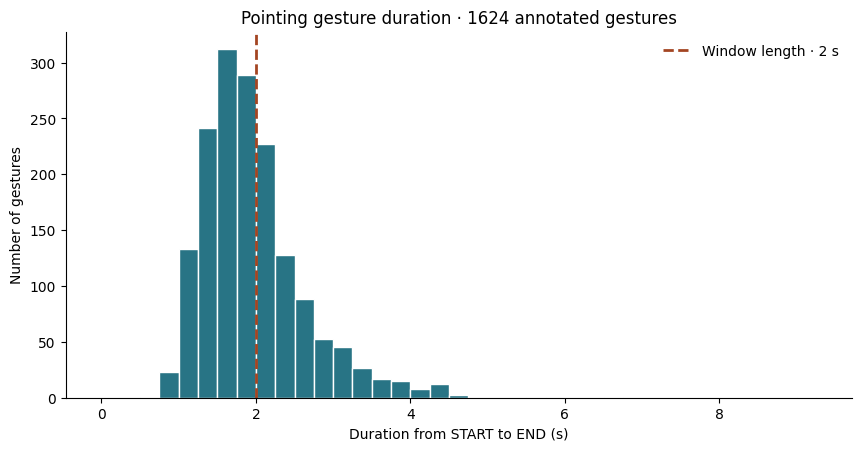

In [9]:
durations = pd.DataFrame(gesture_rows)["duration_s"]
long_gestures = int(durations.gt(WINDOW_S).sum())

duration_stats = pd.DataFrame([{
    "gestures": len(durations),
    "mean_s": durations.mean(),
    "median_s": durations.median(),
    "sample_variance_s2": durations.var(ddof=1),
    "sample_sd_s": durations.std(ddof=1),
    "q1_s": durations.quantile(0.25),
    "q3_s": durations.quantile(0.75),
    "min_s": durations.min(),
    "max_s": durations.max(),
    "window_s": WINDOW_S,
    "longer_than_window": long_gestures,
    "longer_than_window_pct": 100 * long_gestures / len(durations),
}])
duration_stats.to_csv(run_dir / "gesture_duration_statistics.csv", index=False)
display(duration_stats.T.rename(columns={0: "Value"}).round(3))

bin_width_s = 0.25
last_edge = np.ceil(durations.max() / bin_width_s) * bin_width_s
bins = np.arange(0, last_edge + bin_width_s, bin_width_s)
fig, ax = plt.subplots(figsize=(8.5, 4.4), layout="constrained")
ax.hist(durations, bins=bins, color="#287485", edgecolor="white")
ax.axvline(WINDOW_S, color="#a34522", ls="--", lw=2, label=f"Window length · {WINDOW_S:g} s")
ax.set(
    title=f"Pointing gesture duration · {len(durations)} annotated gestures",
    xlabel="Duration from START to END (s)",
    ylabel="Number of gestures",
)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False)
fig.savefig(run_dir / "gesture_duration_histogram.png", dpi=220)
plt.show()


6 · Participant statistics
- Count usable recordings and gestures for each participant.
- Calculate median gesture duration and median START-to-POINTING time.
- Sort participants by gesture count.
- Display the table and save participant_gesture_statistics.csv.

In [10]:
gestures_df = pd.DataFrame(gesture_rows)

participant_stats = (
    gestures_df.groupby(["participant_id", "split"], as_index=False)
    .agg(
        n_recordings=("recording_id", "nunique"),
        n_gestures=("duration_s", "size"),
        median_duration_s=("duration_s", "median"),
        median_start_to_pointing_s=("start_to_pointing_s", "median"),
    )
    .sort_values("n_gestures", ascending=False)
    .reset_index(drop=True)
)

display(participant_stats.round(2))
participant_stats.to_csv(
    run_dir / "participant_gesture_statistics.csv",
    index=False,
)

,participant_id,split,n_recordings,n_gestures,median_duration_s,median_start_to_pointing_s
0,Elena,train,3,81,1.58,0.49
1,Ali,validation,3,79,2.82,0.97
2,Shaghayegh,train,3,79,1.66,0.54
3,Mustafa,train,3,78,1.91,0.92
4,Romain,train,3,78,1.20,0.55
5,Ada,train,3,78,1.88,0.79
6,Parnian,train,3,78,1.32,0.57
7,Sara,validation,3,78,1.23,0.63
8,Martina,test,3,77,2.75,0.92
9,Amirhossein,validation,3,77,1.84,0.73


## 7 · Visual comparison across recordings

- Generate one plot for every successfully processed recording.
- Show the first annotated gesture and automatically select the wrist with the largest START-to-POINTING displacement.
- Use seconds relative to START and shared vertical scales across all recordings.
- Save individual PNG files and a multipage comparison PDF under wrist_plots.
- Display overview pages with up to six recordings each.

Each overview row shows camera and pelvis-centred coordinates for the same recording. Only recordings that passed the earlier checks appear. Wrist selection is automatic and should be checked against the video when tracking looks unusual.


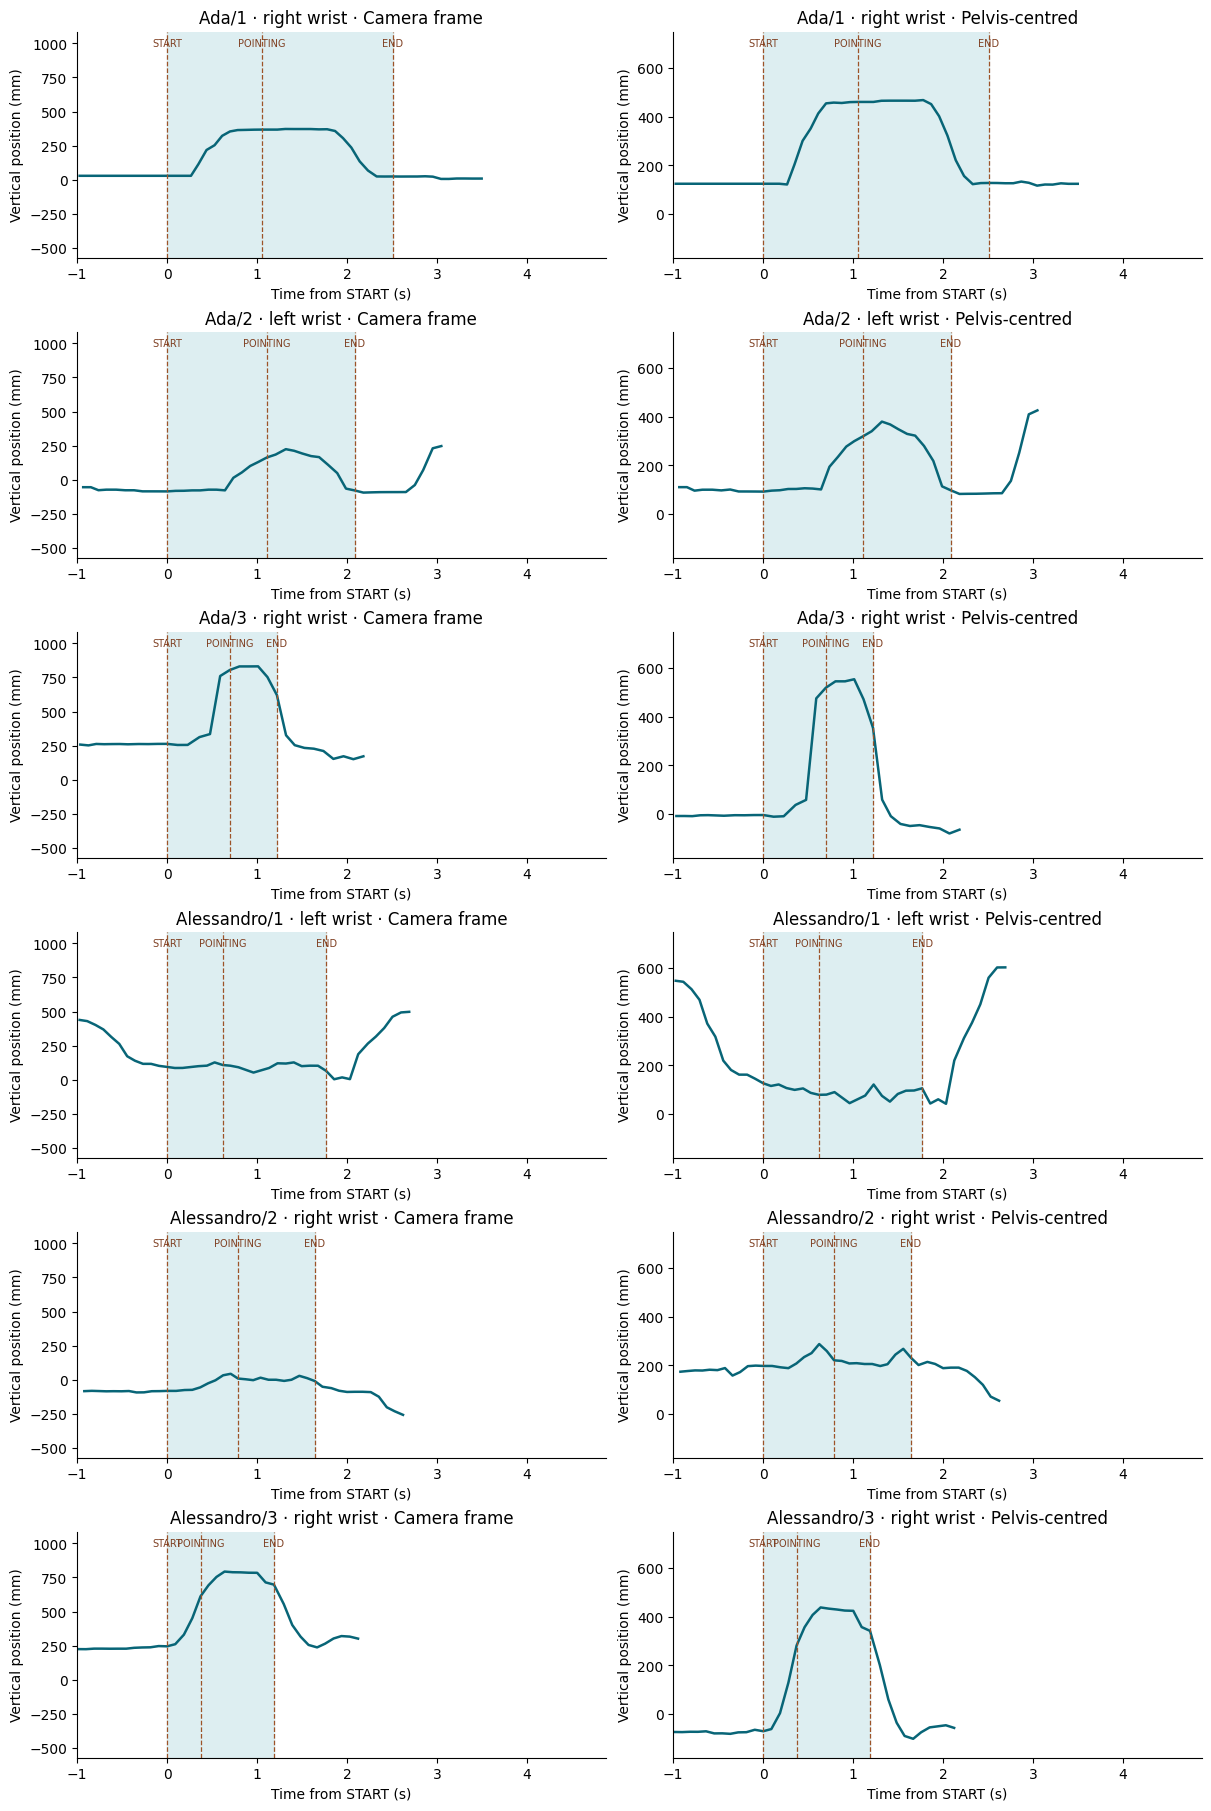

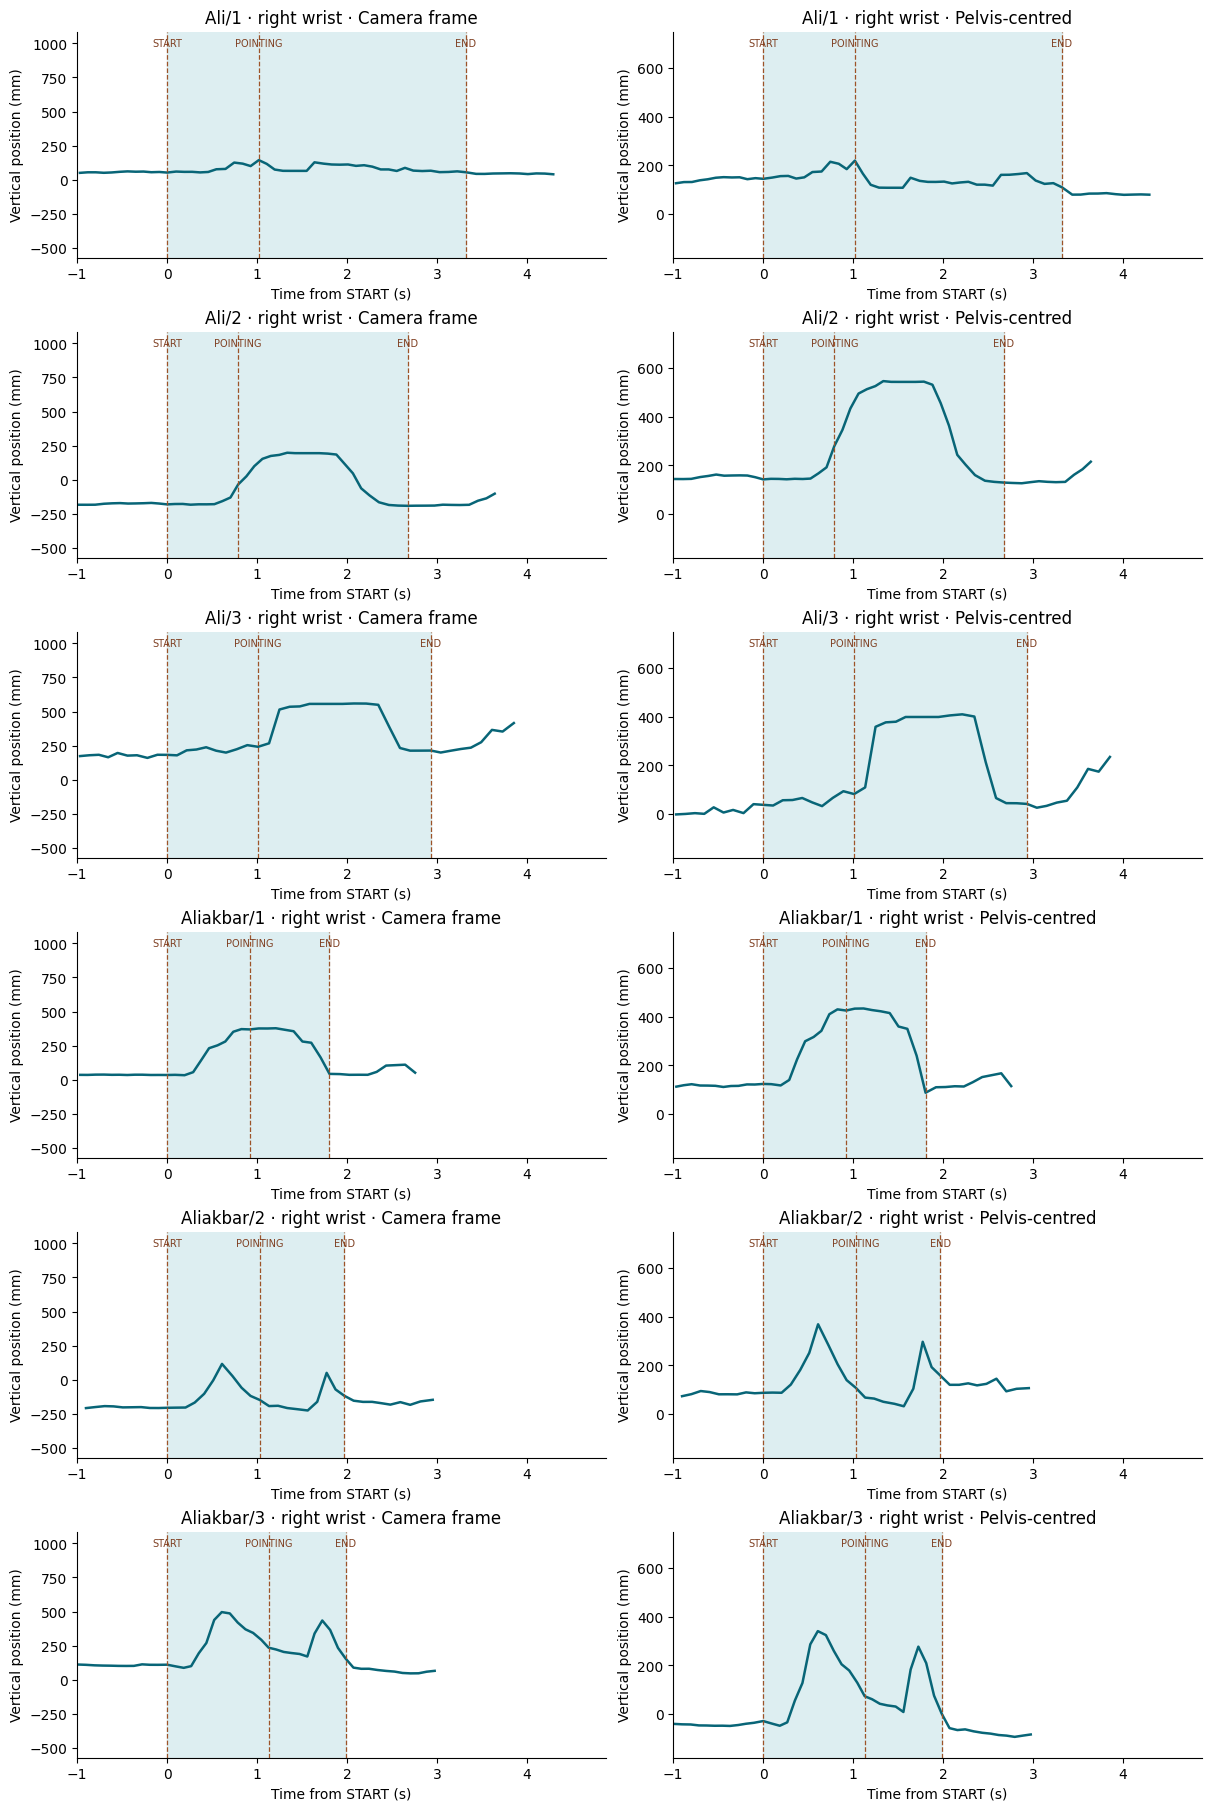

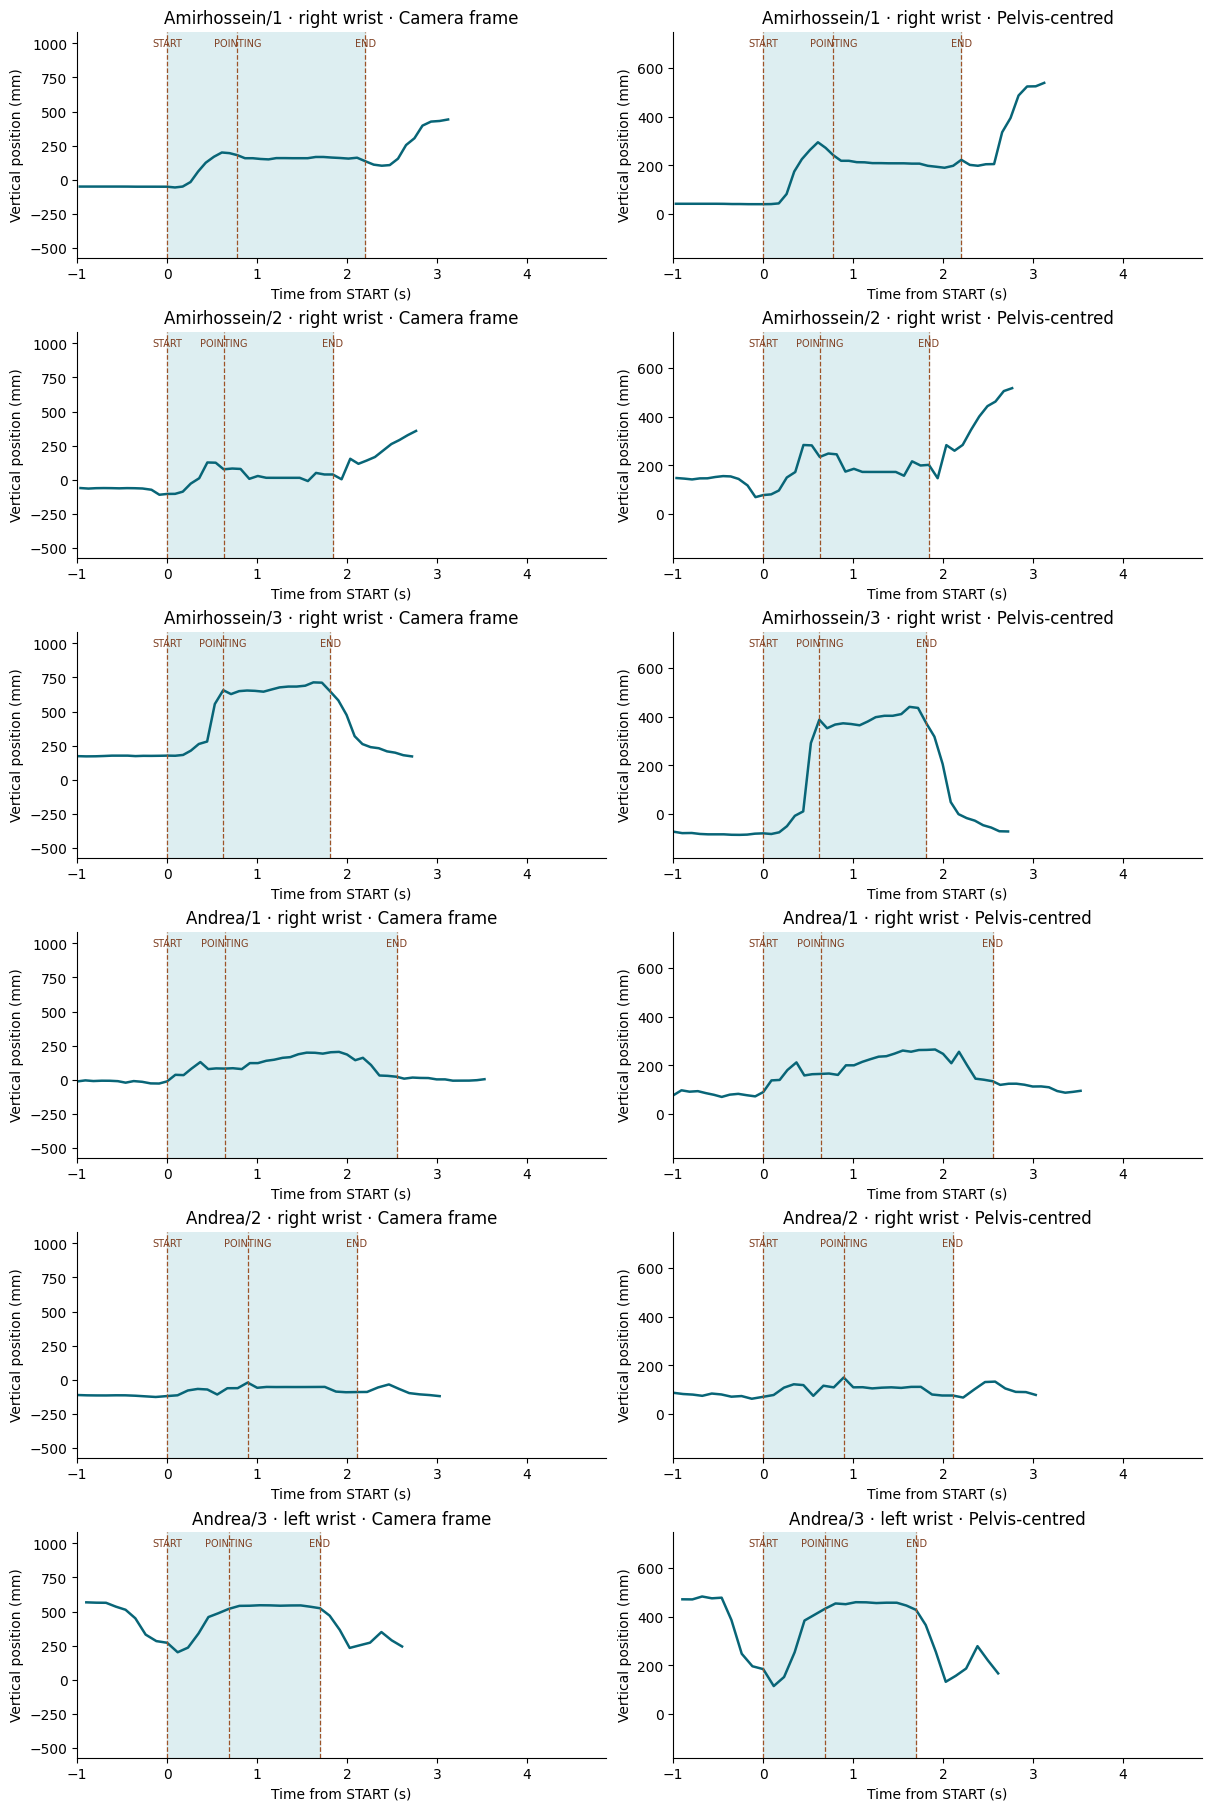

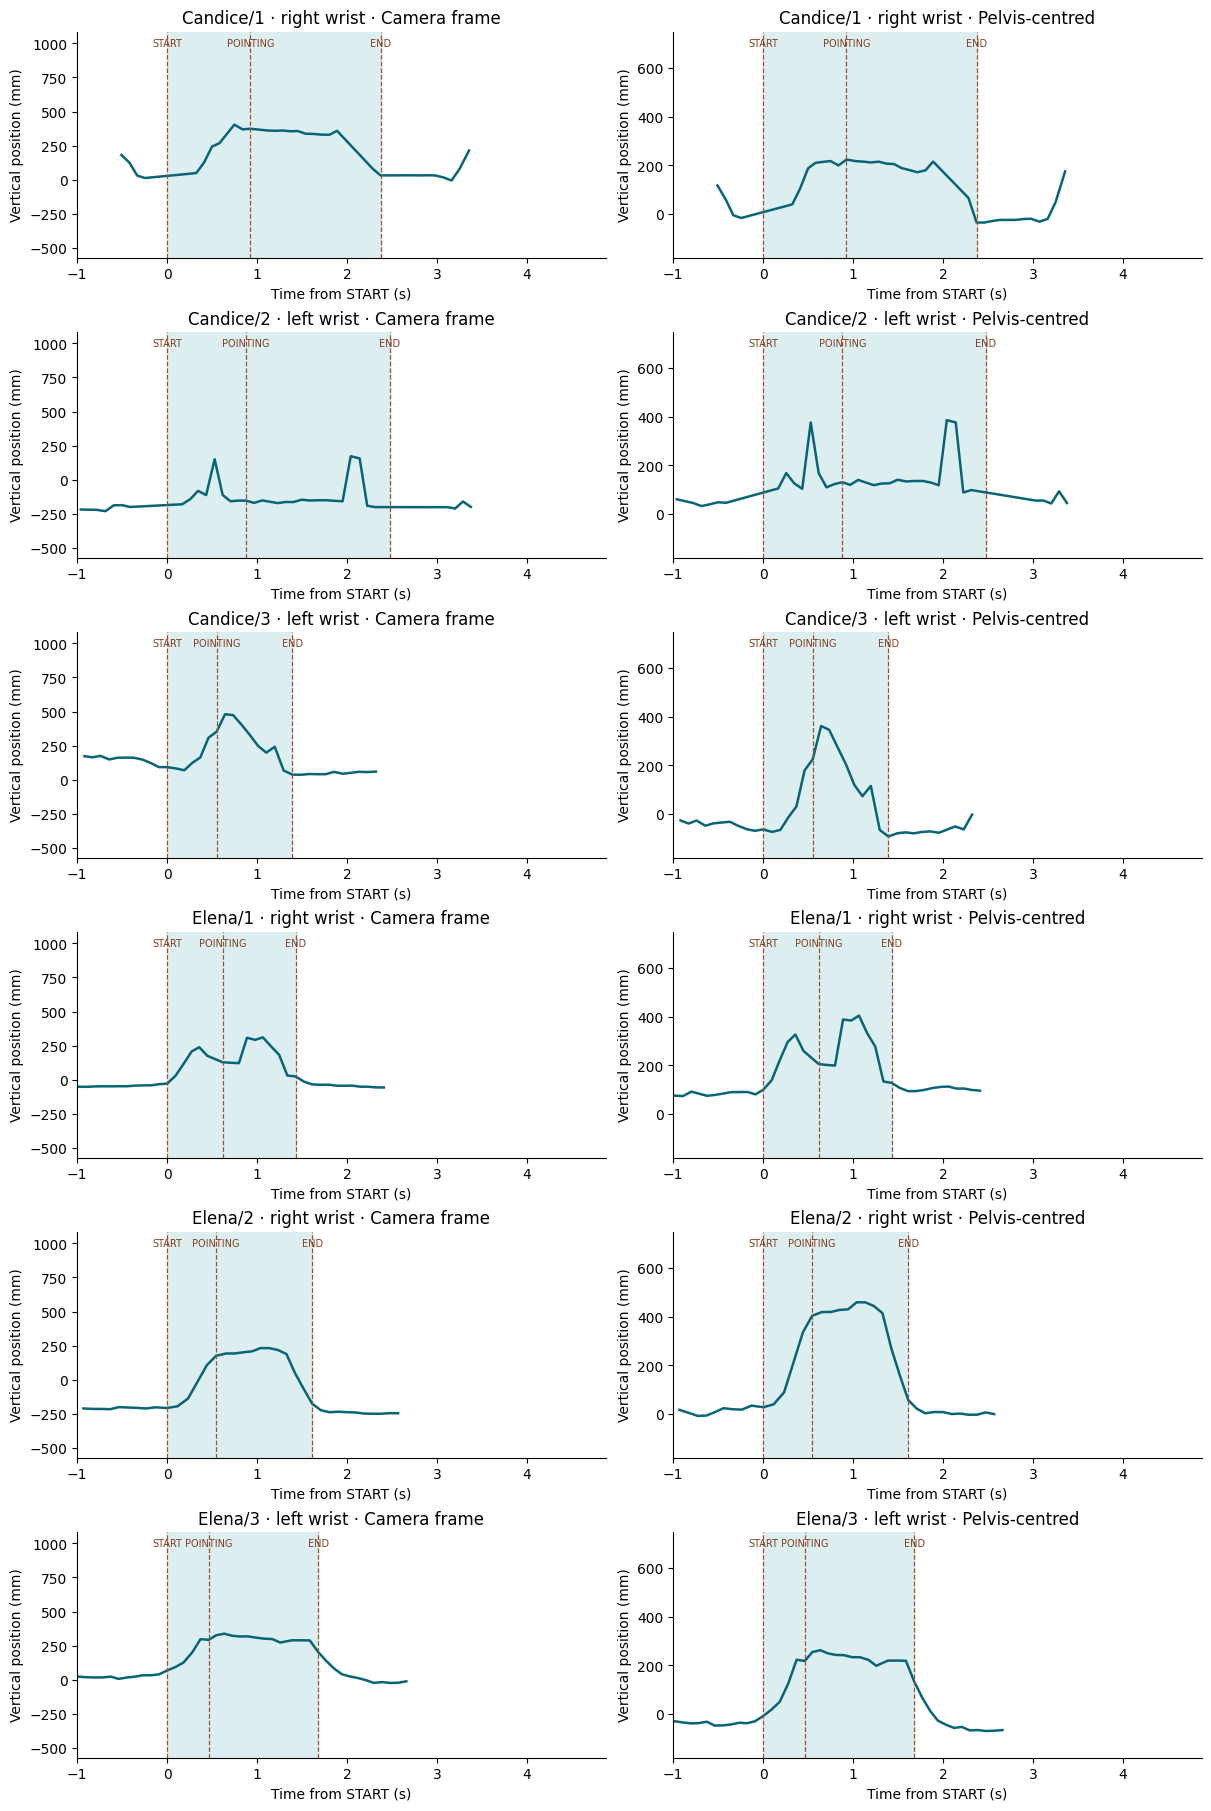

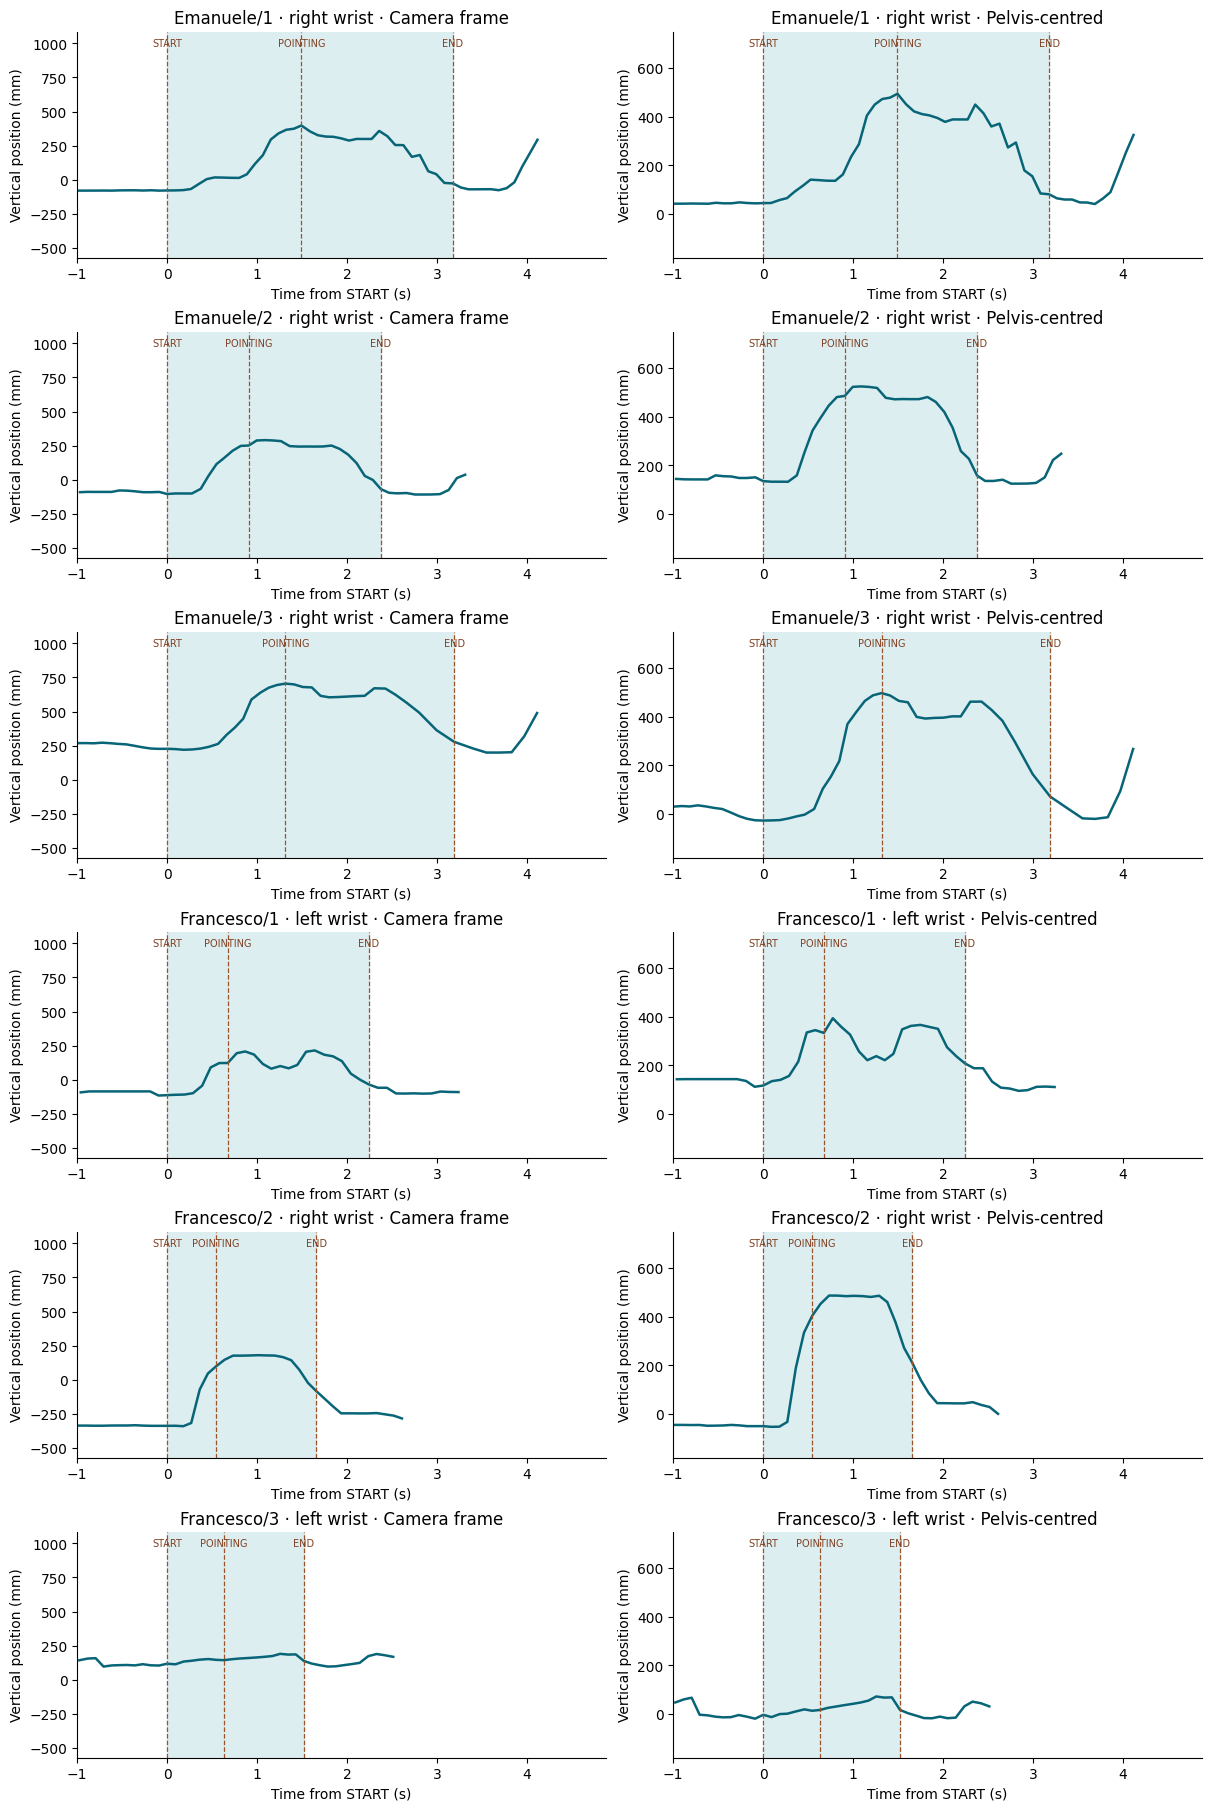

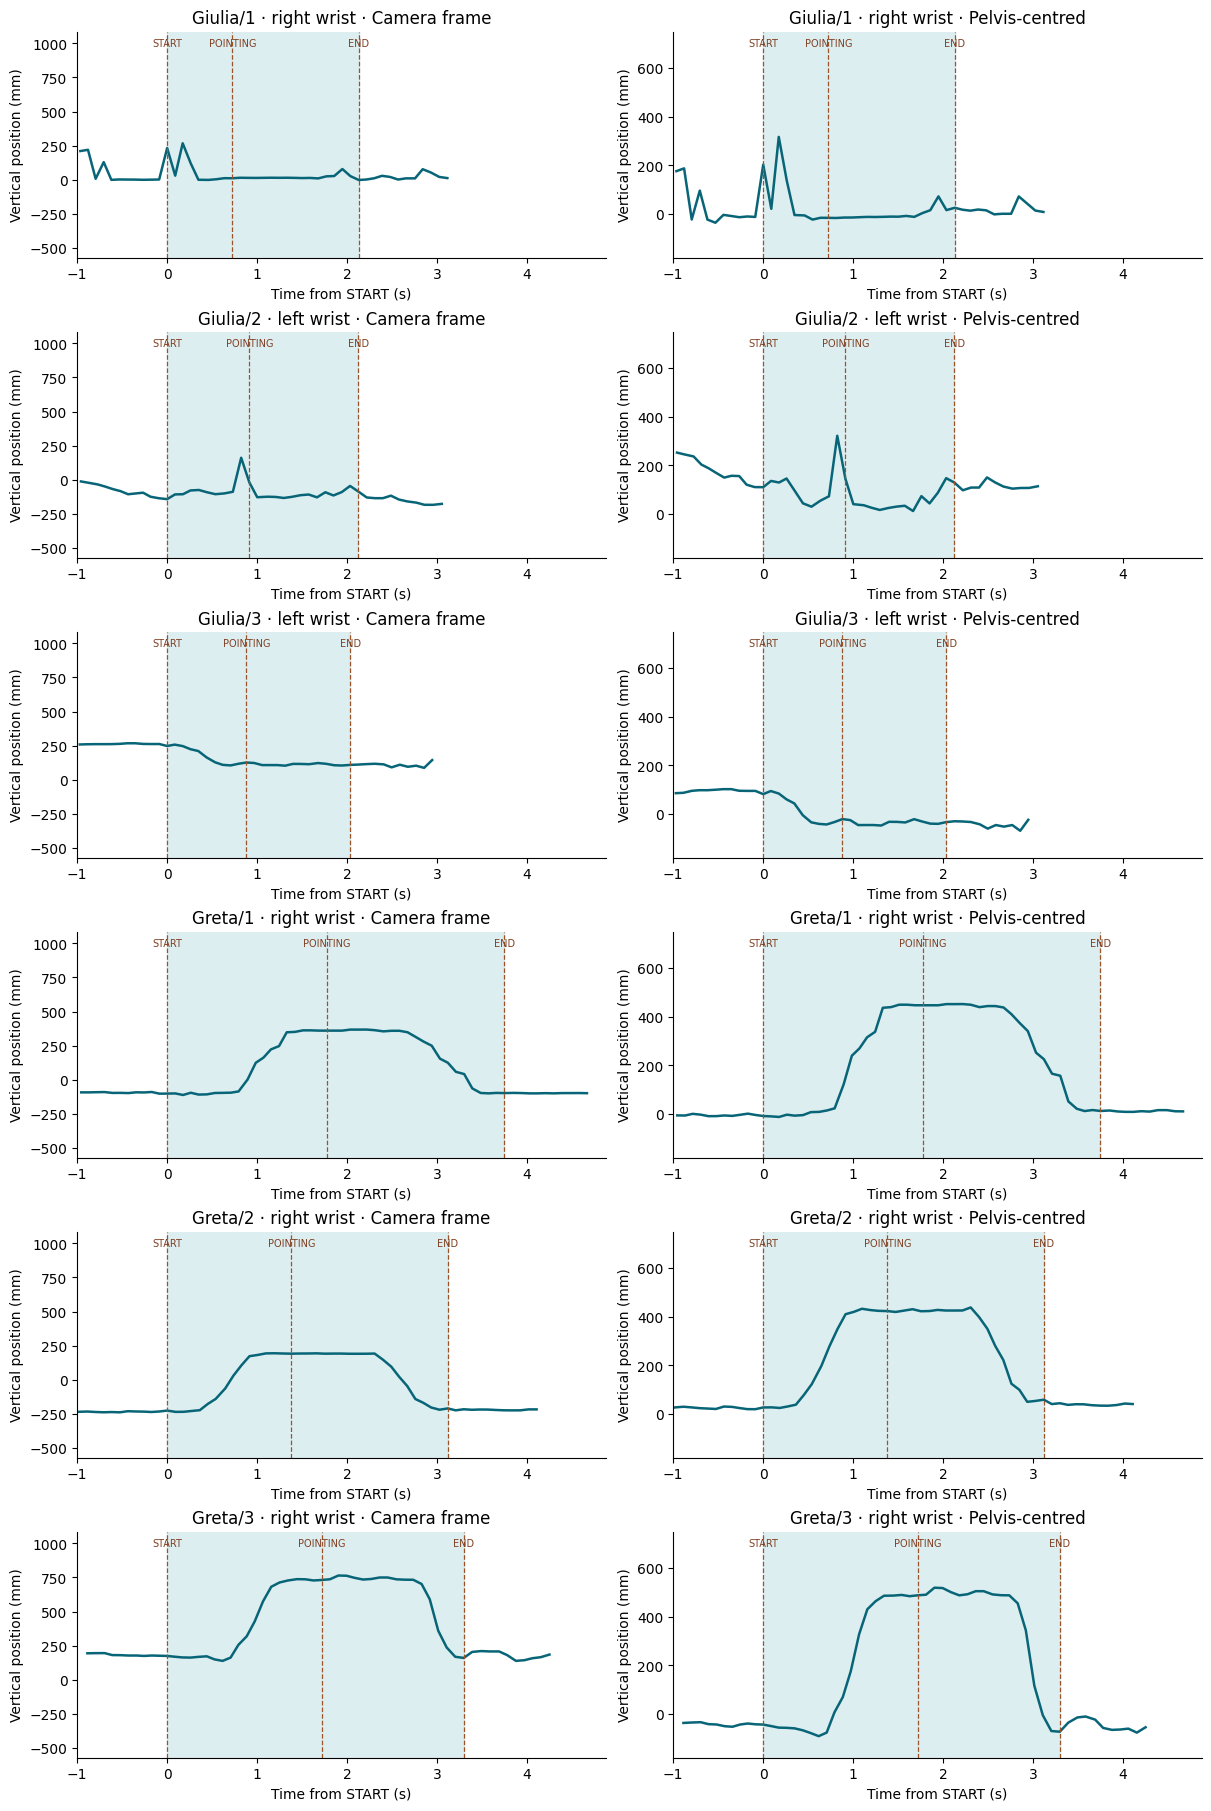

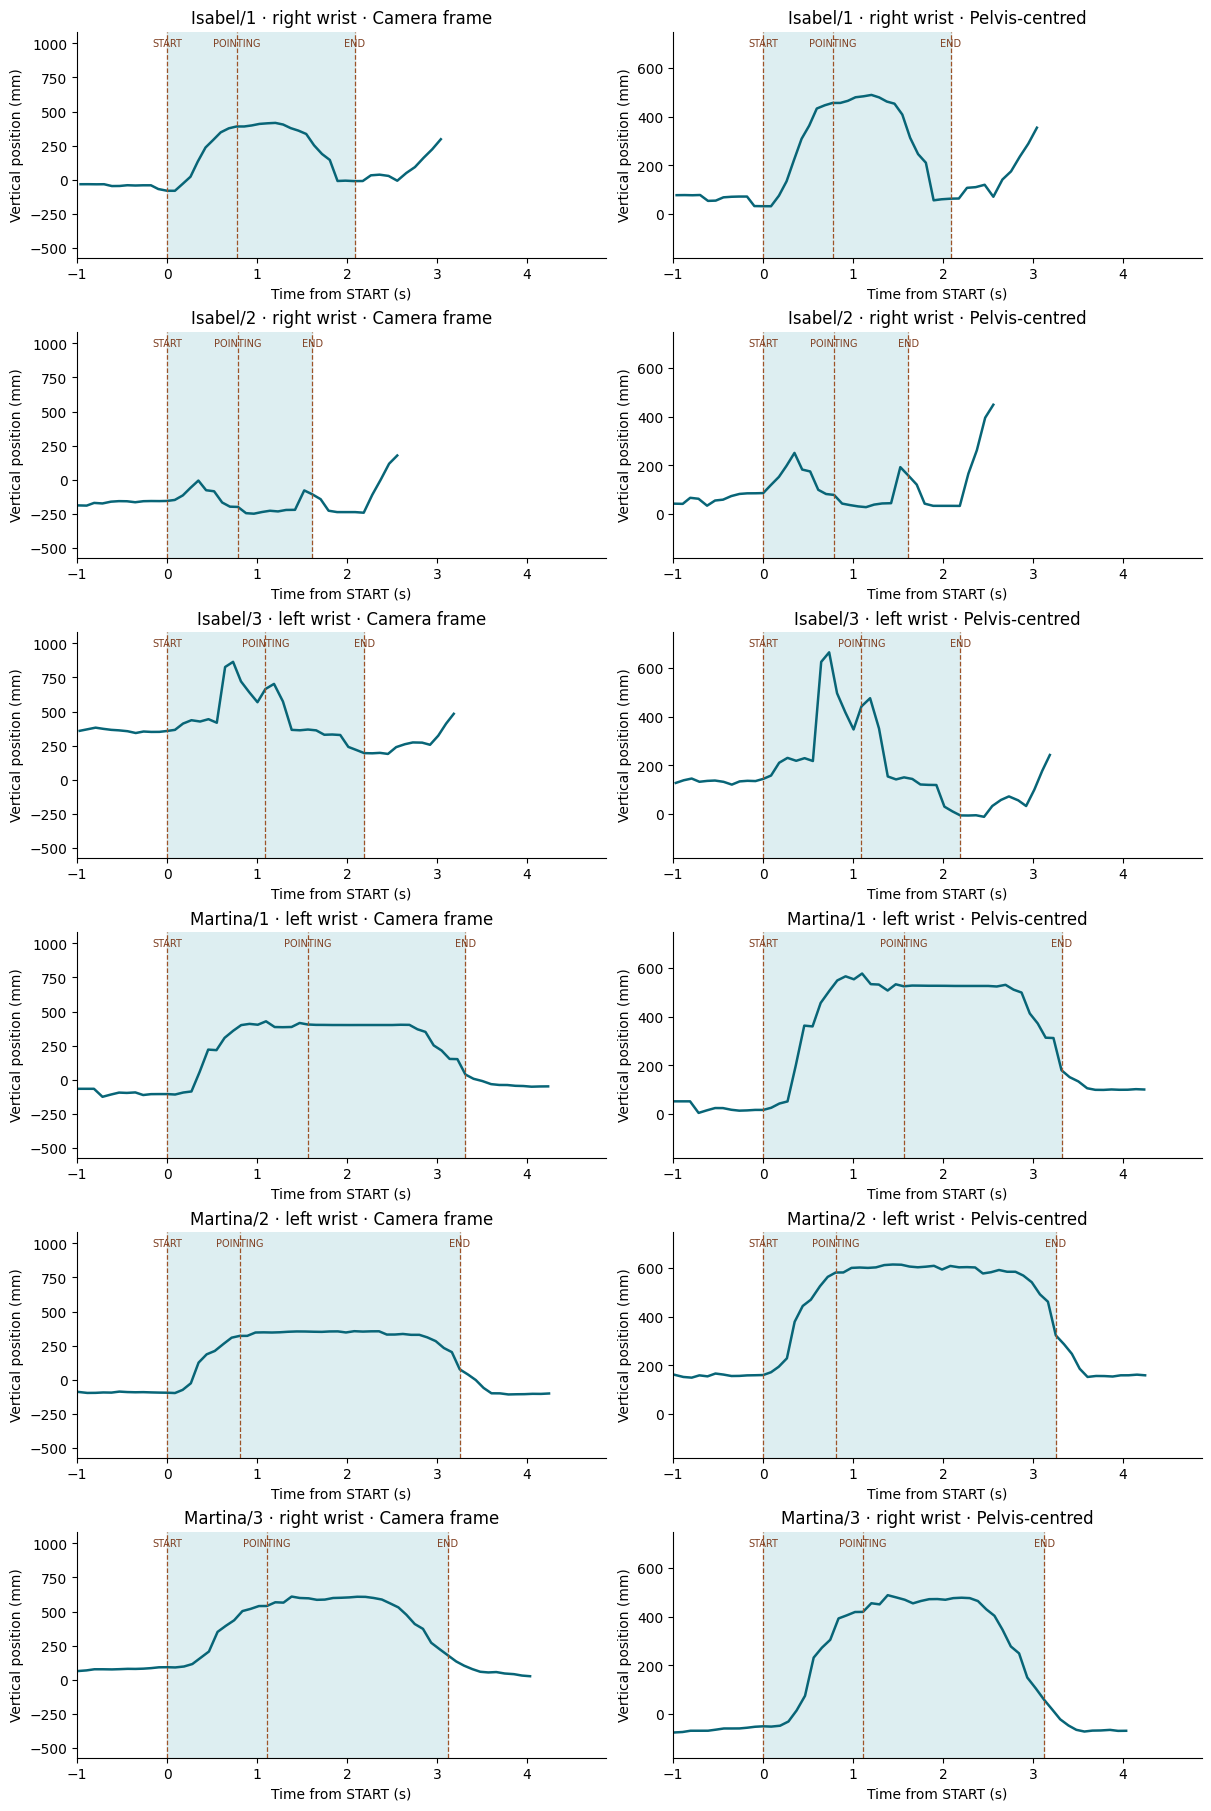

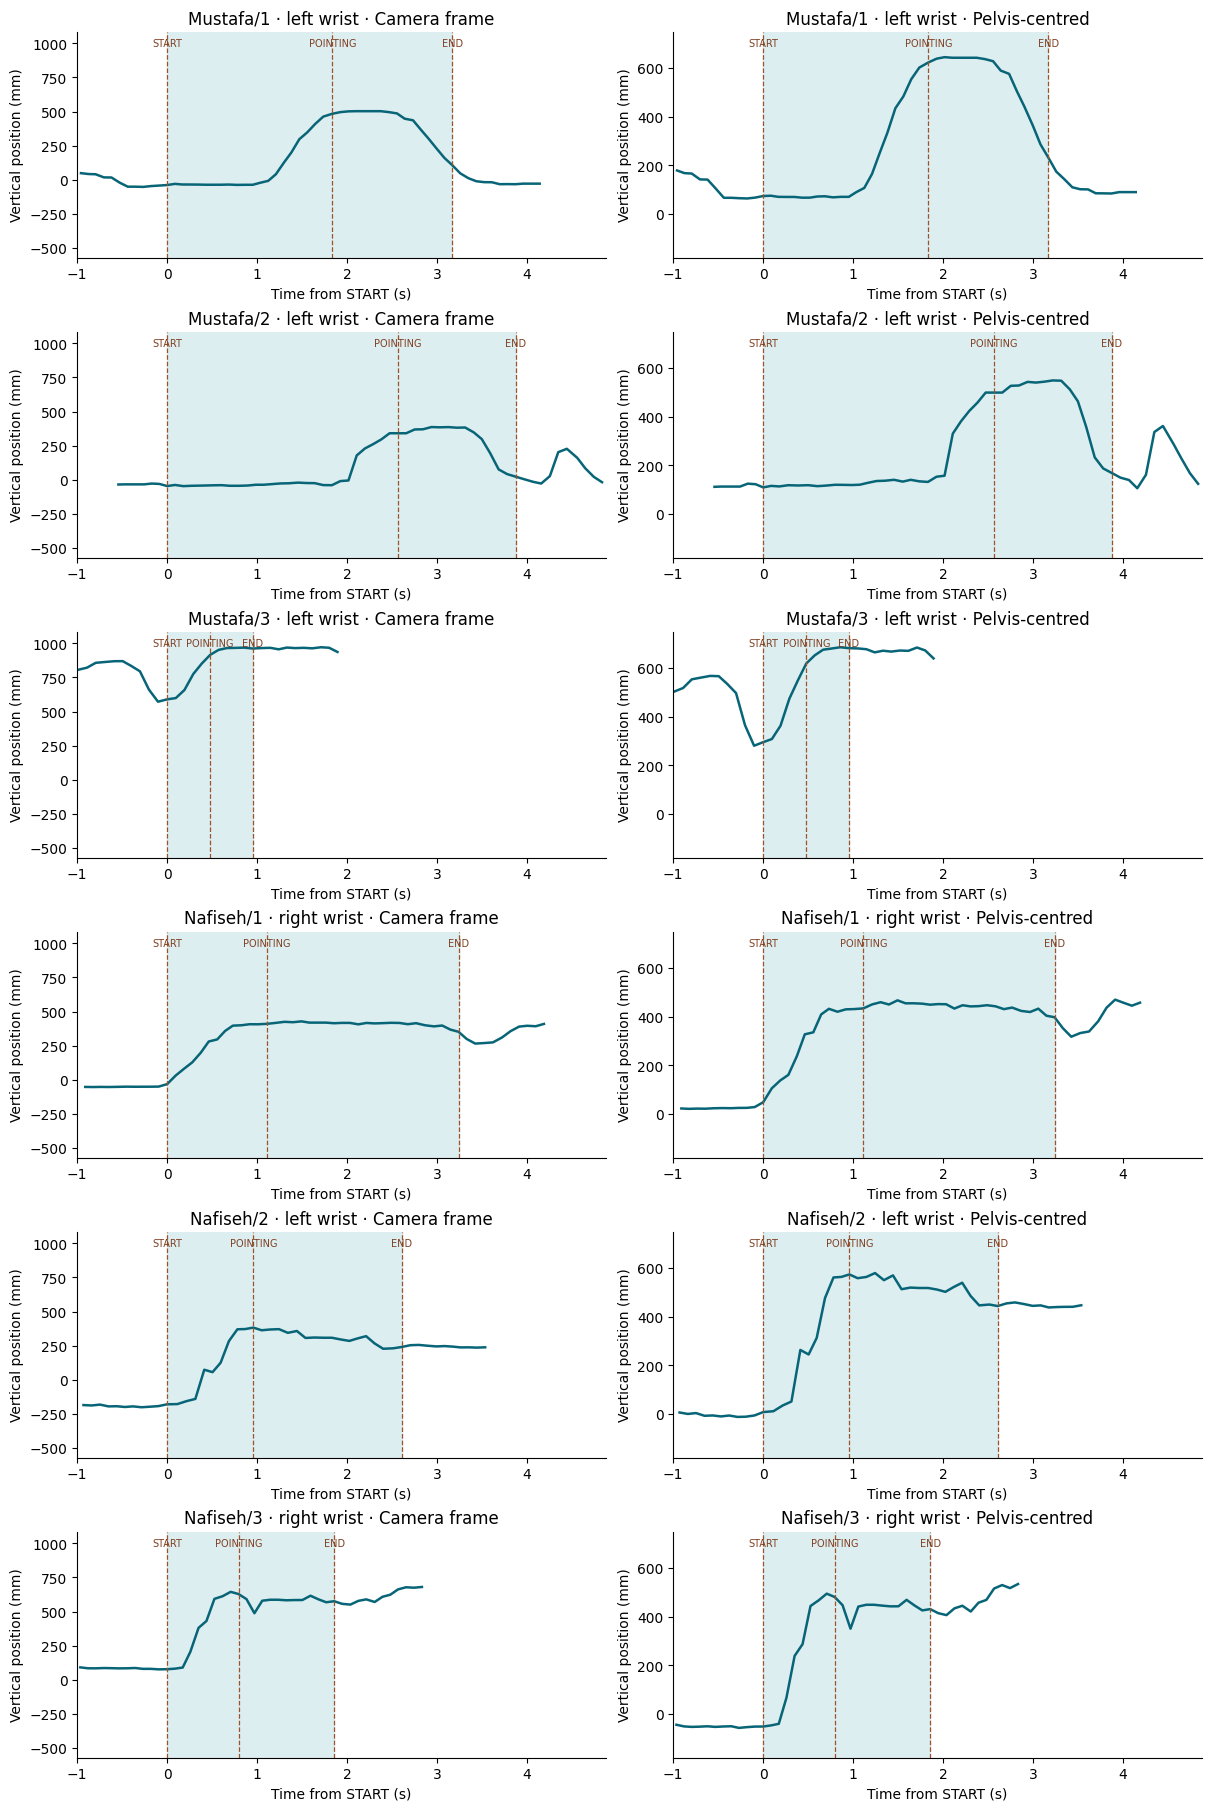

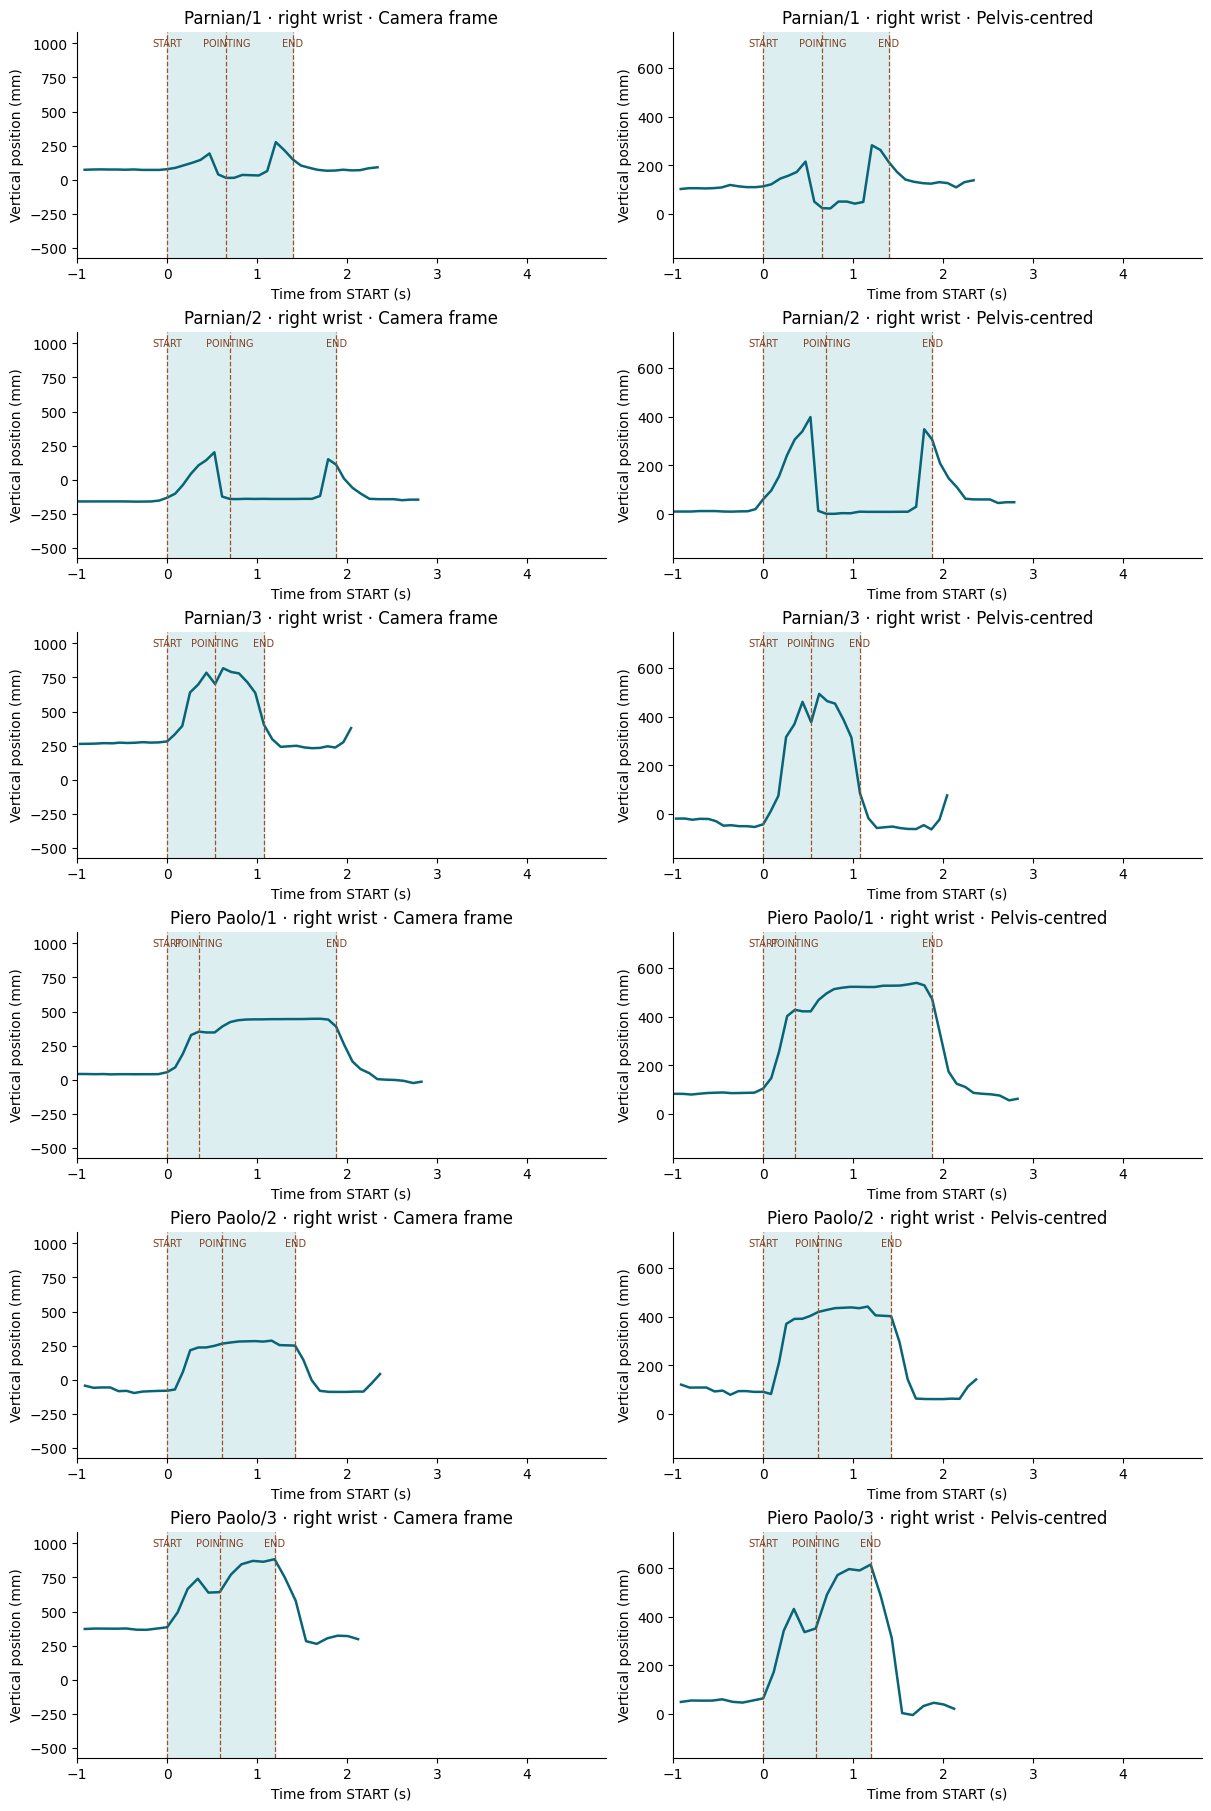

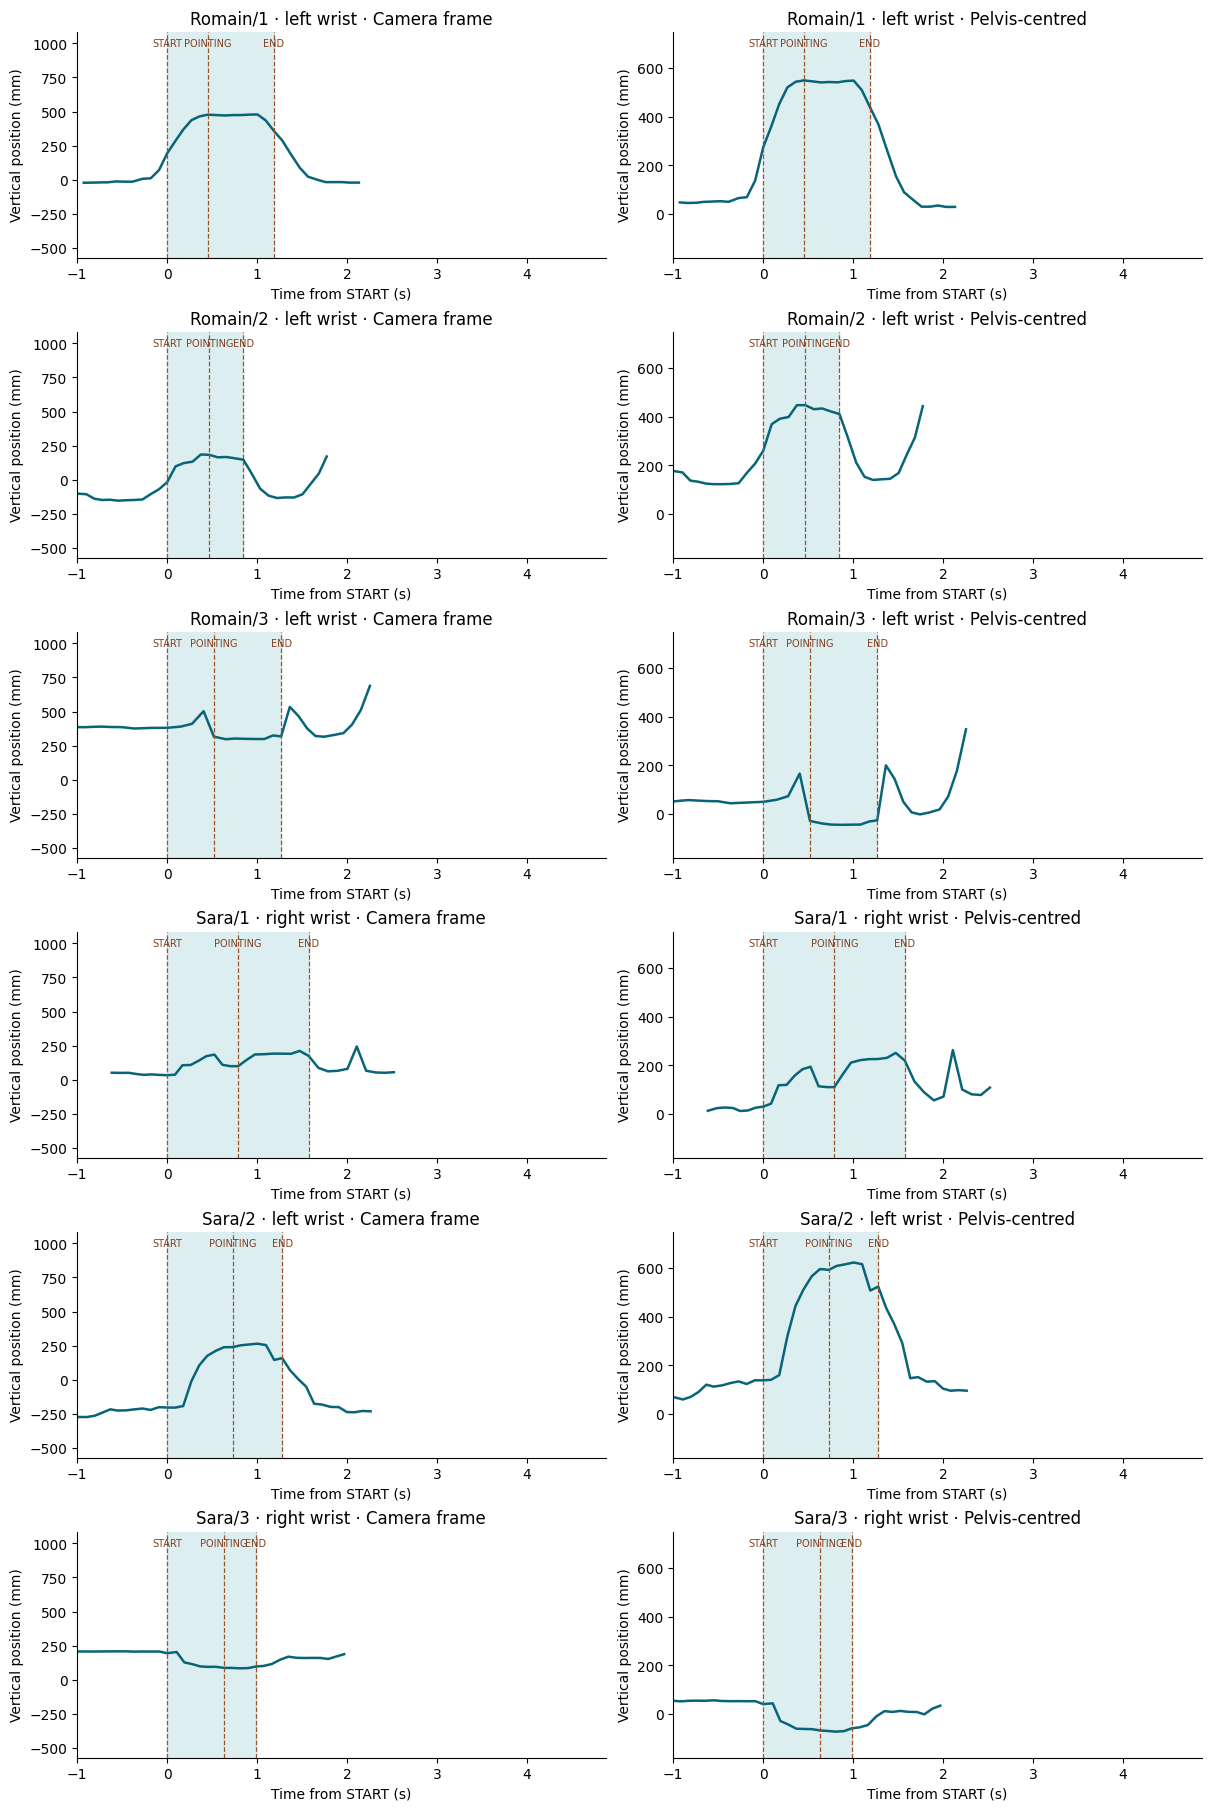

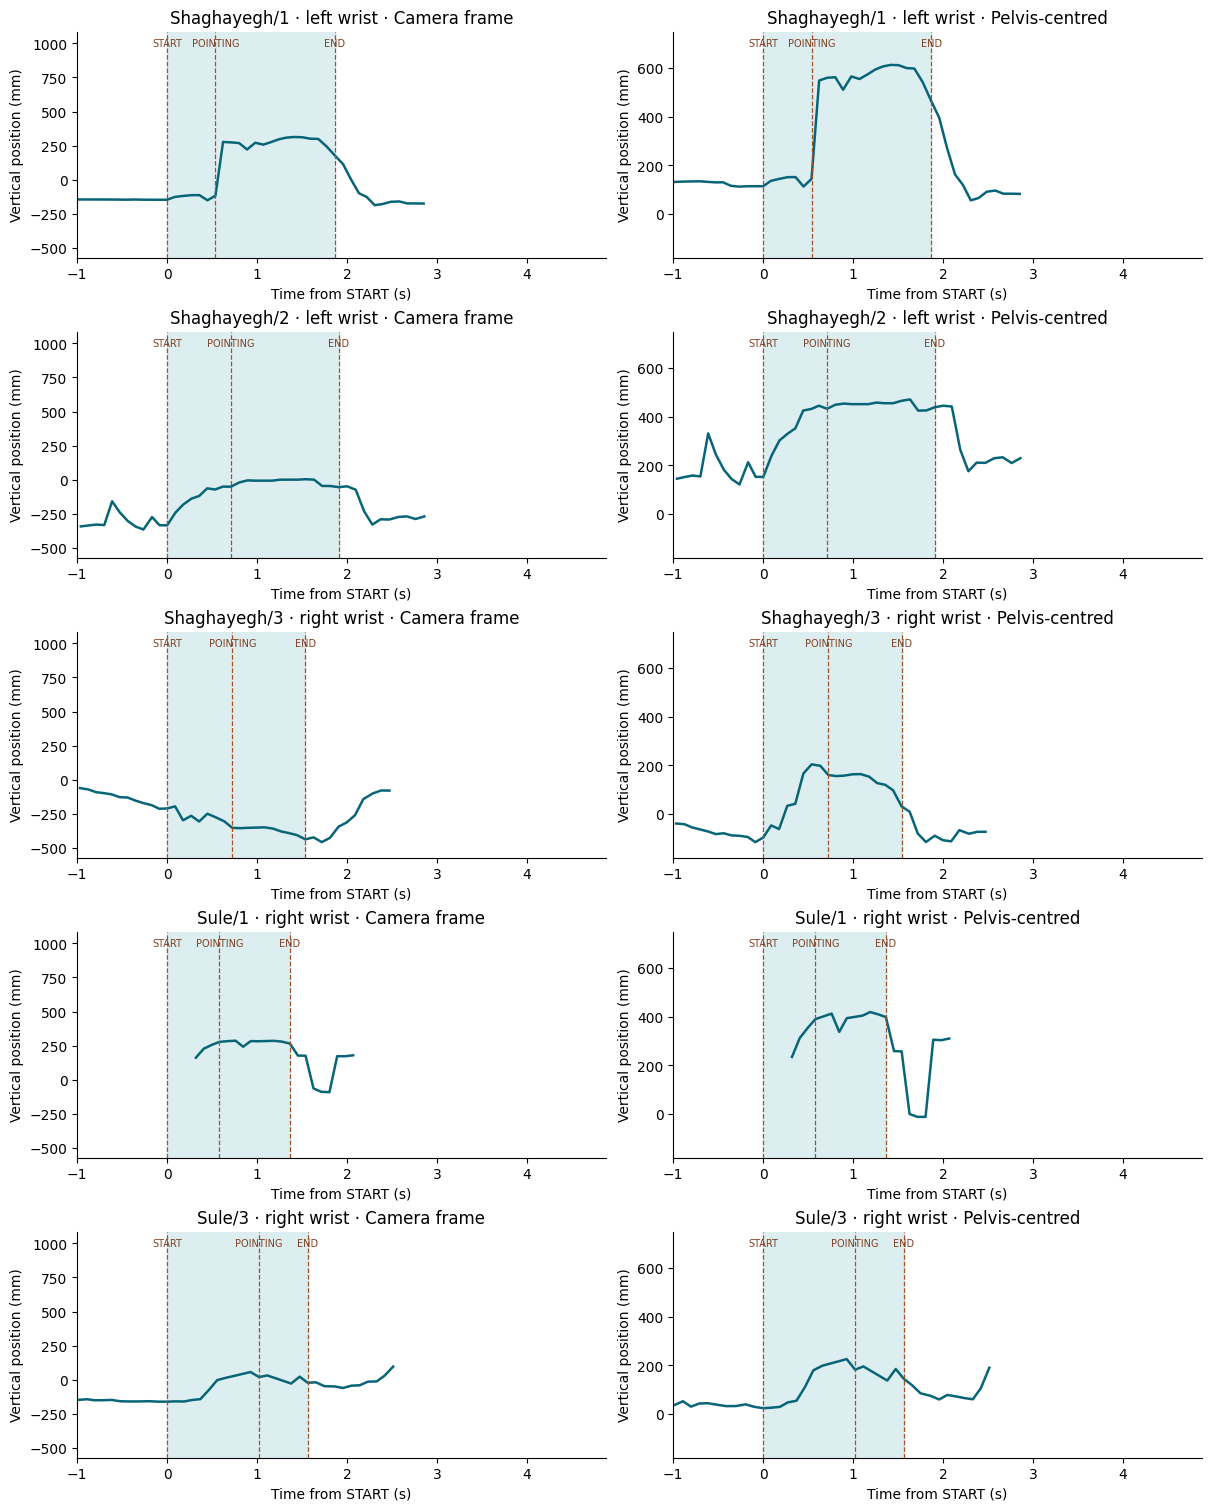

Generated 65 recording plots.
Files saved to /content/drive/MyDrive/pw2_processed/run_ad5x7jfj/wrist_plots


/content/drive/MyDrive/pw2_processed/run_ad5x7jfj/wrist_plots/all_recordings_comparison.pdf

In [11]:
from matplotlib.backends.backend_pdf import PdfPages
from IPython.display import FileLink

plot_dir = run_dir / "wrist_plots"
plot_dir.mkdir(exist_ok=True)
plot_examples = []

for metadata, recording, _ in recordings:
    start, pointing, end = recording["gestures"][0]
    time = recording["time"]
    indices = np.abs(time[:, None] - np.array([start, pointing])).argmin(axis=0)
    displacement = (
        recording["centered"][indices[1], WRISTS, :]
        - recording["centered"][indices[0], WRISTS, :]
    )
    wrist = WRISTS[int(np.linalg.norm(displacement, axis=1).argmax())]
    view = (time >= start - 1) & (time <= end + 1)
    plot_examples.append({
        "recording_id": metadata["recording_id"],
        "time": time[view] - start,
        "camera": -recording["xyz"][view, wrist, 1],
        "centered": -recording["centered"][view, wrist, 1],
        "pointing": pointing - start,
        "end": end - start,
        "side": "left" if wrist == WRISTS[0] else "right",
    })

# Use one vertical scale per coordinate system across the whole comparison.
plot_limits = {}
for coordinate in ("camera", "centered"):
    values = np.concatenate([example[coordinate] for example in plot_examples])
    low, high = values.min(), values.max()
    margin = max((high - low) * 0.08, 10)
    plot_limits[coordinate] = (low - margin, high + margin)
time_limits = (-1, max(example["end"] for example in plot_examples) + 1)


def draw_wrist_pair(axes, example):
    for ax, coordinate, title in zip(
        axes, ("camera", "centered"), ("Camera frame", "Pelvis-centred")
    ):
        ax.axvspan(0, example["end"], color="#ddeef1")
        ax.plot(example["time"], example[coordinate], color="#086577", lw=1.8)
        for instant, label in zip(
            (0, example["pointing"], example["end"]), EVENT_ORDER
        ):
            ax.axvline(instant, ls="--", color="#9d5328", lw=0.9)
            ax.text(
                instant, 0.97, label.upper(),
                transform=ax.get_xaxis_transform(), ha="center", va="top",
                fontsize=7, color="#7f3f21",
            )
        ax.set(
            title=f'{example["recording_id"]} · {example["side"]} wrist · {title}',
            xlabel="Time from START (s)", ylabel="Vertical position (mm)",
            xlim=time_limits, ylim=plot_limits[coordinate],
        )
        ax.spines[["right", "top"]].set_visible(False)


for index, example in enumerate(plot_examples, 1):
    fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), layout="constrained")
    draw_wrist_pair(axes, example)
    fig.savefig(plot_dir / f"recording_{index:04d}.png", dpi=170)
    plt.close(fig)

# A manifest links each filename to its participant and recording.
pd.DataFrame([
    {
        "recording_id": example["recording_id"],
        "selected_wrist": example["side"],
        "plot_file": f"recording_{index:04d}.png",
    }
    for index, example in enumerate(plot_examples, 1)
]).to_csv(plot_dir / "plot_index.csv", index=False)

pdf_path = plot_dir / "all_recordings_comparison.pdf"
with PdfPages(pdf_path) as pdf:
    for offset in range(0, len(plot_examples), 6):
        page = plot_examples[offset:offset + 6]
        fig, axes = plt.subplots(
            len(page), 2, figsize=(12, 3 * len(page)),
            squeeze=False, layout="constrained",
        )
        for row_axes, example in zip(axes, page):
            draw_wrist_pair(row_axes, example)
        pdf.savefig(fig)
        display(fig)
        plt.close(fig)

print(f"Generated {len(plot_examples)} recording plots.")
print(f"Files saved to {plot_dir}")
display(FileLink(str(pdf_path)))


## 8 · ResNet input images
Turns every window into the image format of Laura's ResNet (same recipe as `functions32.py`, all 32 joints):
- **rows = joints** (trunk, head, legs, arms; pointing arm first), **columns = time** (the window's 20 frames resized to 64), **R, G, B = x, y, z**.
- Per frame: pelvis-centred and divided by trunk length (pelvis → spine chest); Savitzky-Golay (5, 2) over time; min-max scaled to 0-255 inside the window; 32 rows stacked twice → **64 × 64 × 3**; CLAHE.
- Labels: `pointing` (window centre inside a gesture) and `no_pointing` (window with no gesture at all). Windows that contain only part of a gesture are kept and labelled by their centre, which keeps the classes at about 57% / 43%; set `KEEP_PARTIAL_BACKGROUND = False` to leave them out. Windows near dropped or badly tracked gestures are always left out.
- Training windows also get a mirrored copy (x negated, left/right swapped), as in Laura's code.
- The participant split from section 3 is kept. Output in `run/resnet/`: `X_<split>.npy` (uint8, divide by 255), `y_<split>.npy` (one-hot), `meta_<split>.csv`, `class_weight.csv`.

In the ResNet notebook: `input_shape = (64, 64, 3)`, `num_classes = 2`, and pass `class_weight` to `model.fit` because pointing is the larger class.


Saved to /content/drive/MyDrive/pw2_processed/run_ad5x7jfj/resnet
Class weights for Keras model.fit(class_weight=...): {0: 1.17, 1: 0.873}


,split,images,shape,pointing,no_pointing,participants
0,train,36412,"(64, 64, 3)",20848,15564,16
1,validation,3510,"(64, 64, 3)",2143,1367,3
2,test,3786,"(64, 64, 3)",2284,1502,3


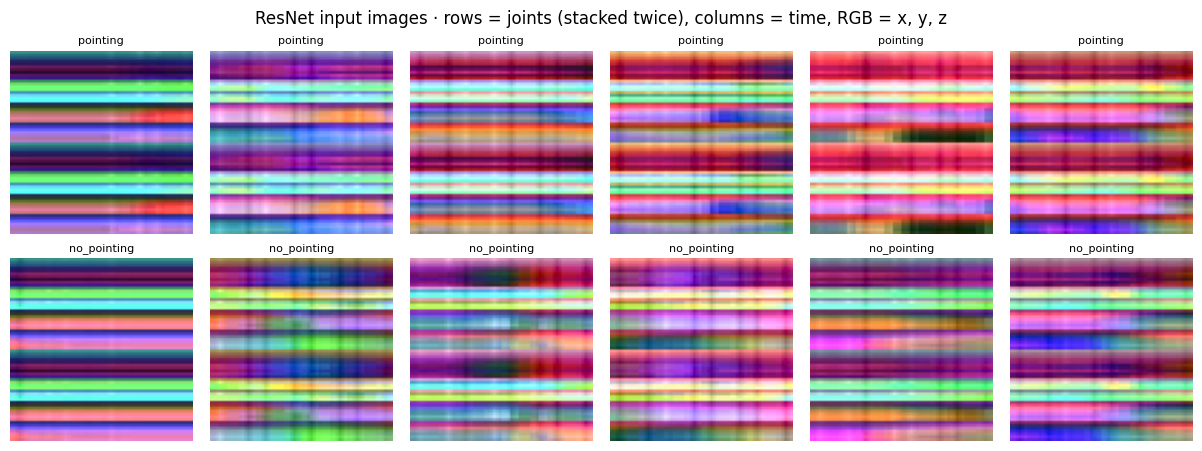

In [12]:
# ResNet input: one RGB image per window, same recipe as Laura's pipeline (functions32.py, 32 joints).
#   rows    = the 32 joints, reordered: trunk, head, legs, then arms (pointing arm first)
#   columns = time (the 20 frames of the window, resized to RESNET_WIDTH columns)
#   R, G, B = x, y, z of each joint, min-max scaled to 0-255 inside the window
# The 32 x RESNET_WIDTH image is stacked twice -> 64 x 64 x 3 with the defaults.
import cv2 as cv
from PIL import Image
from scipy.signal import savgol_filter

RESNET_DIR = run_dir / "resnet"
RESNET_WIDTH = 64            # columns after resizing (Laura: 46 for 23 joints; 64 for 32 joints)
RESNET_STACK = 2             # 32 rows stacked twice -> 64 rows
USE_CLAHE = True             # contrast step from Laura's code
MIRROR_SPLITS = ("train",)   # add a mirrored copy (x negated, left/right arm rows swapped) in these splits
KEEP_PARTIAL_BACKGROUND = True   # True: windows that contain only part of a gesture are kept, labelled by
                                 # their centre (y). False: drop them (cleaner, but ~83% pointing).
EVERY_NTH_WINDOW = 1         # 2 = keep every second window (windows overlap 90% with STEP_S = 0.2)
CLASS_NAMES = ["no_pointing", "pointing"]

SPINE_CHEST = 2
_TRUNK, _LEG_R, _LEG_L = [0, 1, 2, 3], [22, 23, 24, 25], [18, 19, 20, 21]
_HEAD_R, _HEAD_L = [26, 27, 30, 31, 28, 29], [26, 27, 28, 29, 30, 31]
_ARM_R, _ARM_L = [11, 12, 13, 14, 15, 16, 17], [4, 5, 6, 7, 8, 9, 10]
ROW_ORDER = {"right": _TRUNK + _HEAD_R + _LEG_R + _LEG_L + _ARM_R + _ARM_L,
             "left": _TRUNK + _HEAD_L + _LEG_L + _LEG_R + _ARM_L + _ARM_R}


def _clahe(img):
    lab = cv.cvtColor(img, cv.COLOR_RGB2Lab)
    l, a, b = cv.split(lab)
    l = cv.createCLAHE(clipLimit=0.01, tileGridSize=(48, 1)).apply(l)
    return cv.cvtColor(cv.merge((l, a, b)), cv.COLOR_Lab2RGB)


def window_image(window, side="right"):
    """window: (frames, 32, 3), already pelvis-centred. Returns (64, 64, 3) uint8."""
    trunk = np.linalg.norm(window[:, SPINE_CHEST], axis=1)[:, None, None]      # pelvis is (0,0,0)
    data = window / np.maximum(trunk, 1e-6)
    data = data[:, ROW_ORDER[side], :].copy()
    if side == "left":
        data[..., 0] = -data[..., 0]                                             # mirror x
    if len(data) >= 5:
        data = savgol_filter(data, 5, 2, axis=0)
    lo, hi = data.reshape(-1, 3).min(axis=0), data.reshape(-1, 3).max(axis=0)
    color = (255 * (data - lo) / np.maximum(hi - lo, 1e-9)).astype(np.uint8)    # (frames, 32, 3)
    image = np.transpose(color, (1, 0, 2))                                       # (32 joints, frames, 3)
    image = np.asarray(Image.fromarray(image).resize((RESNET_WIDTH, N_JOINTS), resample=Image.NEAREST))
    image = np.concatenate([image] * RESNET_STACK, axis=0)
    return _clahe(image) if USE_CLAHE else image


RESNET_DIR.mkdir(exist_ok=True)
resnet_summary = []
for split_name in ("train", "validation", "test", "demo"):
    files = [run_dir / row["window_file"] for row, _, _ in recordings
             if row.get("split") == split_name]
    if not files:
        continue
    images, labels, meta = [], [], []
    for path in files:
        data = np.load(path)
        keep = np.ones(len(data["y"]), dtype=bool)
        if not KEEP_PARTIAL_BACKGROUND:
            keep &= ~((data["y"] == 0) & data["overlaps_gesture"])
        keep &= (np.arange(len(keep)) % EVERY_NTH_WINDOW) == 0
        for i in np.where(keep)[0]:
            sides = ["right", "left"] if split_name in MIRROR_SPLITS else ["right"]
            for side in sides:
                images.append(window_image(data["X"][i], side))
                labels.append(int(data["y"][i]))
                meta.append({"participant_id": str(data["participant_id"]),
                             "recording_id": str(data["recording_id"]),
                             "window_start_s": float(data["window_start_s"][i]),
                             "label": int(data["y"][i]), "mirrored": side == "left"})
    X_img = np.asarray(images, dtype=np.uint8)
    y_int = np.asarray(labels, dtype=np.int64)
    y_onehot = np.eye(len(CLASS_NAMES), dtype=np.float32)[y_int]
    np.save(RESNET_DIR / f"X_{split_name}.npy", X_img)          # uint8 0-255; divide by 255 before training
    np.save(RESNET_DIR / f"y_{split_name}.npy", y_onehot)
    pd.DataFrame(meta).to_csv(RESNET_DIR / f"meta_{split_name}.csv", index=False)
    resnet_summary.append({"split": split_name, "images": len(X_img), "shape": str(X_img.shape[1:]),
                           "pointing": int(y_int.sum()), "no_pointing": int((y_int == 0).sum()),
                           "participants": len({m["participant_id"] for m in meta})})

resnet_summary = pd.DataFrame(resnet_summary)
train_counts = np.bincount(np.load(RESNET_DIR / "y_train.npy").argmax(1), minlength=2) \
    if (RESNET_DIR / "y_train.npy").exists() else np.ones(2)
class_weight = {i: float(train_counts.sum() / (len(CLASS_NAMES) * max(c, 1))) for i, c in enumerate(train_counts)}
pd.Series(class_weight, name="class_weight").to_csv(RESNET_DIR / "class_weight.csv")
print(f"Saved to {RESNET_DIR}")
print("Class weights for Keras model.fit(class_weight=...):", {k: round(v, 3) for k, v in class_weight.items()})
display(resnet_summary)

# Show a few examples: pointing (top) and no pointing (bottom) from the training set.
if (RESNET_DIR / "X_train.npy").exists():
    X_show, y_show = np.load(RESNET_DIR / "X_train.npy", mmap_mode="r"), np.load(RESNET_DIR / "y_train.npy").argmax(1)
    fig, axes = plt.subplots(2, 6, figsize=(12, 4.4), layout="constrained")
    for row_axes, label in zip(axes, (1, 0)):
        picks = np.where(y_show == label)[0]
        picks = picks[np.linspace(0, len(picks) - 1, min(6, len(picks))).astype(int)] if len(picks) else []
        for ax in row_axes:
            ax.axis("off")
        for ax, i in zip(row_axes, picks):
            ax.imshow(X_show[i]); ax.set_title(CLASS_NAMES[label], fontsize=8)
    fig.suptitle("ResNet input images · rows = joints (stacked twice), columns = time, RGB = x, y, z")
    plt.show()
